# **Predicción de Fuga de Clientes (Churn) en Telecomunicaciones**

    Autores: Felipe Huincaman & David Ramírez
    Fecha de Actualización: 14 de Noviembre, 2026
    Asignatura: Machine Learning
    Docente: Profesora Jazna Meza Hidalgo

##### **Requisitos de Software**
Para la correcta ejecución del código en este notebook, se requiere un entorno de **Python 3.12** o superior con las siguientes librerías instaladas:

    Manejo y análisis de datos: 
        pandas 3.1.1
        numpy 2.5.4
        scipy 1.18.1

    Visualización: 
        matplotlib 3.11.2
        seaborn 0.13.2
    Preprocesamiento y Machine Learning: 
        scikit-learn 1.9.1

##### **Importación de Librerías**

In [2]:
%pip install kneed

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\huinc\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\huinc\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [4]:
# 1. SISTEMA Y RUTAS
import os
import sys
import hashlib

# Configuración de rutas del proyecto
sys.path.insert(0, os.path.abspath("../"))

# 2. MANIPULACIÓN Y ANÁLISIS DE DATOS
import numpy as np
import pandas as pd
import scipy.stats as ss
from IPython.display import display

# 3. VISUALIZACIÓN DE DATOS
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import plot_tree

# 4. PREPROCESAMIENTO Y PIPELINES
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    MinMaxScaler,
    OneHotEncoder,
    OrdinalEncoder
)

# 5. MODELOS DE MACHINE LEARNING
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier

# 6. DIVISIÓN DE DATOS Y OPTIMIZACIÓN
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    KFold
)
from kneed import KneeLocator

# 7. EVALUACIÓN DE MODELOS (MÉTRICAS)
from sklearn.metrics import (
    make_scorer,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    mean_squared_error,
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
    silhouette_score
)

# 8. MÓDULOS LOCALES DEL PROYECTO
import src.visualizaciones as visualizaciones
from src.visualizaciones import plot_matriz_confusion, plot_curva_roc
from src.feature_engineering import TelcoFeatureEngineer

# 9. CONFIGURACIONES DE LIBRERÍAS
# Configurar la salida de los transformadores como DataFrame
sklearn.set_config(transform_output="pandas")

In [5]:
from importlib.metadata import version, PackageNotFoundError

# Versiones de las librerías utilizadas
paquetes = [
    "numpy",
    "pandas",
    "scipy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "kneed",
    "xgboost"
]

# Mostrar versión de Python
print(f"Python: {sys.version.split()[0]}\n")

# Mostrar versiones de las librerías
for paquete in paquetes:
    try:
        print(f"{paquete}: {version(paquete)}")
    except PackageNotFoundError:
        print(f"{paquete}: No instalado")

Python: 3.11.9

numpy: 2.4.6
pandas: 3.0.3
scipy: 1.17.1
matplotlib: 3.11.0
seaborn: 0.13.2
scikit-learn: 1.9.0
kneed: 0.8.6
xgboost: 3.2.0


### **Funciones**

In [6]:
# Función para comparar la optimización de hiperparámetros entre RandomizedSearchCV y GridSearchCV
def comparar_optimizacion_clasificacion(
    pipeline,
    param_random,
    param_grid,
    X_train,
    y_train,
    X_test,
    y_test,
    n_iter=20,
    scoring='f1',
    cv_splits=5,
    random_state=42
):
    cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=random_state)
    resultados = []
    mejores_modelos = {}

    busquedas = {
        'RandomizedSearchCV': RandomizedSearchCV(
            estimator=clone(pipeline),
            param_distributions=param_random,
            n_iter=n_iter,
            scoring=scoring,
            cv=cv,
            n_jobs=1,
            random_state=random_state,
            pre_dispatch=1
        ),
        'GridSearchCV': GridSearchCV(
            estimator=clone(pipeline),
            param_grid=param_grid,
            scoring=scoring,
            cv=cv,
            n_jobs=1,
            pre_dispatch=1
        )
    }

    for nombre, search in busquedas.items():
        search.fit(X_train, y_train)

        mejor_modelo = search.best_estimator_
        mejores_modelos[nombre] = mejor_modelo

        # Predicciones sobre el conjunto de prueba
        y_pred = mejor_modelo.predict(X_test)
        y_prob = mejor_modelo.predict_proba(X_test)[:, 1]

        resultados.append({
            'Método': nombre,
            'Mejor Score CV': round(search.best_score_, 4),
            'F1 Test': round(f1_score(y_test, y_pred), 4),
            'Recall Test': round(recall_score(y_test, y_pred), 4),
            'Precision Test': round(precision_score(y_test, y_pred), 4),
            'ROC-AUC Test': round(roc_auc_score(y_test, y_prob), 4),
            'Mejores Hiperparámetros': search.best_params_
        })

    df_comparacion = pd.DataFrame(resultados)
    return df_comparacion, mejores_modelos

In [7]:
# Función para comparar la optimización de hiperparámetros entre RandomizedSearchCV y GridSearchCV para regresión
def comparar_optimizacion_regresion(
    pipeline,
    param_random,
    param_grid,
    X_train,
    y_train,
    X_test,
    y_test,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv_splits=5,
    random_state=42,
):
    cv = KFold(n_splits=cv_splits, shuffle=True, random_state=random_state)
    resultados = []
    mejores_modelos = {}

    busquedas = {
        "RandomizedSearchCV": RandomizedSearchCV(
            estimator=clone(pipeline),
            param_distributions=param_random,
            n_iter=n_iter,
            scoring=scoring,
            cv=cv,
            n_jobs=1,
            verbose=1,
            random_state=random_state,
        ),
        "GridSearchCV": GridSearchCV(
            estimator=clone(pipeline),
            param_grid=param_grid,
            scoring=scoring,
            cv=cv,
            n_jobs=1,
            verbose=1,
        ),
    }

    for nombre, search in busquedas.items():
        search.fit(X_train, y_train)

        mejor_modelo = search.best_estimator_
        mejores_modelos[nombre] = mejor_modelo

        y_pred = mejor_modelo.predict(X_test)

        best_cv = -search.best_score_ if scoring.startswith("neg_") else search.best_score_

        resultados.append({
            "Método": nombre,
            "Mejor RMSE CV": round(best_cv, 4),
            "RMSE Test": round(root_mean_squared_error(y_test, y_pred), 4),
            "MAE Test": round(mean_absolute_error(y_test, y_pred), 4),
            "R2 Test": round(r2_score(y_test, y_pred), 4),
            "Mejores Hiperparámetros": search.best_params_,
        })

    return pd.DataFrame(resultados), mejores_modelos

In [8]:
# Función para obtener feature importance
def obtener_feature_importance(pipeline_entrenado, top_n=15, graficar=True, titulo="Feature Importance"):
    preprocesador = pipeline_entrenado.named_steps['preprocesador']
    modelo = pipeline_entrenado.named_steps['modelo']

    # nombres de las columnas transformadas
    try:
        nombres_features = preprocesador.get_feature_names_out()
    except AttributeError:
        # en caso de que algún transformador interno no implemente get_feature_names_out
        nombres_features = [f"Feature_{i}" for i in range(modelo.n_features_in_)]

    # Limpiar prefijos
    nombres_limpios = [nombre.split('__')[-1] for nombre in nombres_features]

    # importancias según el tipo de modelo
    if hasattr(modelo, 'feature_importances_'):
        # Para DecisionTree, RandomForest, XGBoost
        valores = modelo.feature_importances_
        metrica = "Importancia"
    elif hasattr(modelo, 'coef_'):
        # Para LinearRegression, LogisticRegression
        valores = np.abs(modelo.coef_.ravel())
        metrica = "Coeficiente Absoluto (|coef|)"
    else:
        raise ValueError("El modelo no tiene atributos 'feature_importances_' ni 'coef_'.")

    # DataFrame ordenado
    df_imp = (
        pd.DataFrame({
            'Feature': nombres_limpios,
            metrica: valores
        })
        .sort_values(by=metrica, ascending=False)
        .reset_index(drop=True)
    )

    # Top N
    if graficar:
        df_top = df_imp.head(top_n)
        plt.figure(figsize=(10, max(5, top_n * 0.35)))
        sns.barplot(data=df_top, x=metrica, y='Feature', palette='viridis', hue='Feature', legend=False)
        plt.title(f"{titulo} (Top {top_n})", fontsize=13, fontweight='bold')
        plt.xlabel(metrica)
        plt.ylabel("")
        plt.grid(axis='x', linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

    return df_imp

# **1. Comprensión de los Datos**

##### **Lectura de Datos**

In [9]:
df = pd.read_csv("https://raw.githubusercontent.com/david-ramirezl/data/refs/heads/main/Telco_Customer_Churn_Dataset.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## **1.1 Descripción del Conjunto de Datos**

### **1.1.1 Descripción de Características**

| Variable | Descripción |
| :--- | :--- |
| `customerID` | Identificador único de cada cliente. |
| `gender` | Género del cliente (Female = mujer, Male = hombre). |
| `SeniorCitizen` | Indica si el cliente es adulto mayor (1 = sí, 0 = no). |
| `Partner` | Indica si el cliente tiene pareja (Yes = sí, No = no). |
| `Dependents` | Indica si el cliente tiene personas dependientes a su cargo (Yes = sí, No = no). |
| `tenure` | Antigüedad del cliente en la empresa, expresada en meses. |
| `PhoneService` | Indica si el cliente tiene contratado servicio telefónico (Yes = sí, No = no). |
| `MultipleLines` | Indica si el cliente tiene múltiples líneas telefónicas (Yes = sí, No = no, No phone service = sin servicio telefónico). |
| `InternetService` | Tipo de servicio de Internet contratado (DSL, Fiber optic o No). |
| `OnlineSecurity` | Indica si el cliente tiene contratado el servicio de seguridad en línea (Yes = sí, No = no, No internet service = sin Internet). |
| `OnlineBackup` | Indica si el cliente tiene contratado el servicio de respaldo en línea (Yes = sí, No = no, No internet service = sin Internet). |
| `DeviceProtection` | Indica si el cliente tiene contratado el servicio de protección de dispositivos (Yes = sí, No = no, No internet service = sin Internet). |
| `TechSupport` | Indica si el cliente tiene contratado soporte técnico (Yes = sí, No = no, No internet service = sin Internet). |
| `StreamingTV` | Indica si el cliente tiene contratado el servicio de televisión por streaming (Yes = sí, No = no, No internet service = sin Internet). |
| `StreamingMovies` | Indica si el cliente tiene contratado el servicio de películas por streaming (Yes = sí, No = no, No internet service = sin Internet). |
| `Contract` | Tipo de contrato del cliente (Month-to-month = mensual, One year = anual, Two year = dos años). |
| `PaperlessBilling` | Indica si el cliente utiliza facturación electrónica (Yes = sí, No = no). |
| `PaymentMethod` | Método de pago utilizado (Electronic check = cheque electrónico, Mailed check = cheque enviado por correo, Bank transfer (automatic) = transferencia bancaria automática, Credit card (automatic) = tarjeta de crédito automática). |
| `MonthlyCharges` | Cargo mensual que paga el cliente por los servicios contratados. |
| `TotalCharges` | Monto total facturado al cliente durante su permanencia en la empresa. |
| `Churn` | Indica si el cliente abandonó la empresa (Yes = sí, No = no). |

### **1.1.2 Información Básica del Conjunto**

In [10]:
# Mostrar un resumen conciso del DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Observaciones:**
* Este conjunto de datos consiste en **7043** registros y **21** características.
* El dataset tiene muchas características como data de texto y probablemente sean variables categóricas.
* **TotalCharges** contiene valores numéricos pero está almacenada como strings. Vamos a convertir esta variable a tipo numérica (float).
* La variable **SeniorCitizen** indica si el cliente es adulto mayor (0 = "no", 1 = "sí"). Al ser una variable categórica, la convertiremos de tipo numérico a object.

## **1.2 Manipulación de Datos**

In [11]:
# convertir columnas de tipo string a object
for columna in df.select_dtypes(include=['string']).columns:
        df[columna] = df[columna].astype('object')
print(f"Total de columnas convertidas a object: {len(df.select_dtypes(include=['object']).columns)}")

Total de columnas convertidas a object: 18


In [12]:
# convertir TotalCharges a numérico
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("TotalCharges convertido a numérico.")

TotalCharges convertido a numérico.


In [13]:
# convertir SeniorCitizen a object para que sea categórico
df['SeniorCitizen'] = df['SeniorCitizen'].replace({0: 'No', 1: 'Sí'}).astype(object)
print("SeniorCitizen convertido a object.")

SeniorCitizen convertido a object.


In [14]:
df.dtypes

customerID           object
gender               object
SeniorCitizen        object
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

* La variable objetivo que guiará nuestra exploración es el **Churn**.

## **1.3 Implementación de Anonimización**

Para evitar conservar directamente el identificador original de los clientes, se genera una representación mediante la función hash SHA-256. De esta manera, se mantiene una referencia técnica para identificar registros sin almacenar el valor original en el DataFrame.

Posteriormente, se elimina la columna customerID y se conserva su representación hash.

In [15]:
def anonimizar(texto):
    # Genera un hash único para el identificador (irreversible)
    return hashlib.sha256(texto.encode('utf-8')).hexdigest()

# Aplicar a la columna sensible
df['customerID_Hash'] = df['customerID'].apply(anonimizar)

# Eliminar el dato original
df = df.drop(columns=['customerID'])

In [16]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,customerID_Hash
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,f3f9002e121cbbcc038f195a656a32a17395c6ce1815e8...
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,5f362546eb7515f442a40d3d9bf632e4a481c92bcb0529...
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,701bf78bdf332d16ec5fb80a1affac3a080a8b9c258c2d...
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,59a0e1b332a6b6ba8f6a72f74085e6498e8c54a5d18191...
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,66370db9e1bb6a851fa692a2499f4f1356efab8e5abf90...


## **1.4 Estadísticas Descriptivas del Conjunto**

### **1.4.1 Estadísticas descriptivas de las variables numéricas**

Analicemos las estadísticas descriptivas de nuestras variables numéricas:

In [17]:
# estadísticas descriptivas de variables numéricas
df.describe(include=np.number).T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


**Variables Numéricas:**
- La antiguedad mediana es de 29 meses, mientras que la media es de 32,37 meses
- Los cargos mensuales tienen una mediana de $70,35, con valores entre $18,25 y $118,75
- **TotalCharges** presenta una mediana de $1394,55 y una media de $2279,73

### **1.4.2 Estadísticas descriptivas de las variables categóricas**

A continuación, revisemos las estadísticas descriptivas de las características categóricas:

In [18]:
# Obtener las estadísticas descriptivas de las variables categóricas
df.select_dtypes(
    include=['object', 'string']
).drop(
    columns=['customerID_Hash'],
    errors='ignore'
).describe().T

,count,unique,top,freq
gender,7043,2,Male,3555
SeniorCitizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


**Variables categóricas (tipo de dato object):**
* La distribución por género es equilibrada: hay 3555 hombres y 3488 mujeres
* La clase positiva **Churn = Yes**, que representa a los clientes que sí abandonan el servicio, contiene 1869 registros (26,5%)
* La mayoría de los clientes no son adultos mayores: la categoría SeniorCitizen = No representa aproximadamente el 83,8% del conjunto.
* El contrato más frecuente es mensual, con 3875 clientes, lo que representa aproximadamente el 55%
* Cerca del 90,3% de los clientes tiene servicio telefónico

## **1.5 EDA**

### **1.5.1 Variable Objetivo**

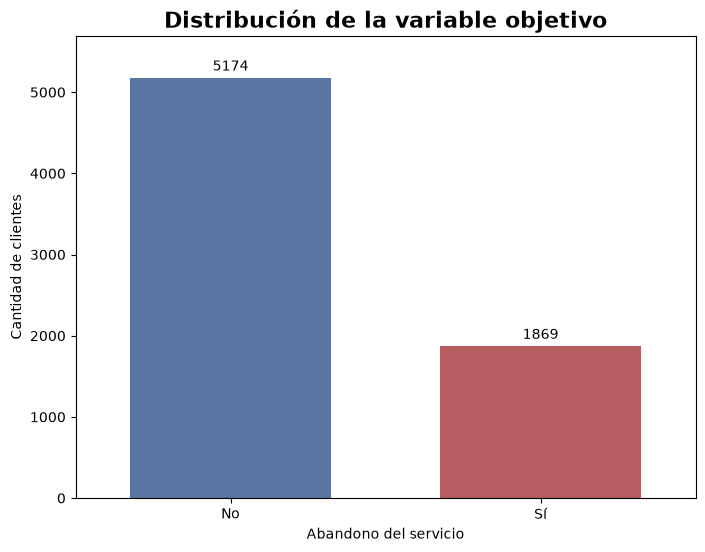

In [19]:
fig, ax = visualizaciones.graficar_distribucion_churn(df)
plt.show()

* La tasa general de churn es del **26.5%**. Veamos entonces los distintos grupos de clientes. ¿Qué grupos presentan una mayor probabilidad de abandono?

### **1.5.2 Análisis Univariado**

#### **Análisis univariado de variables numéricas**

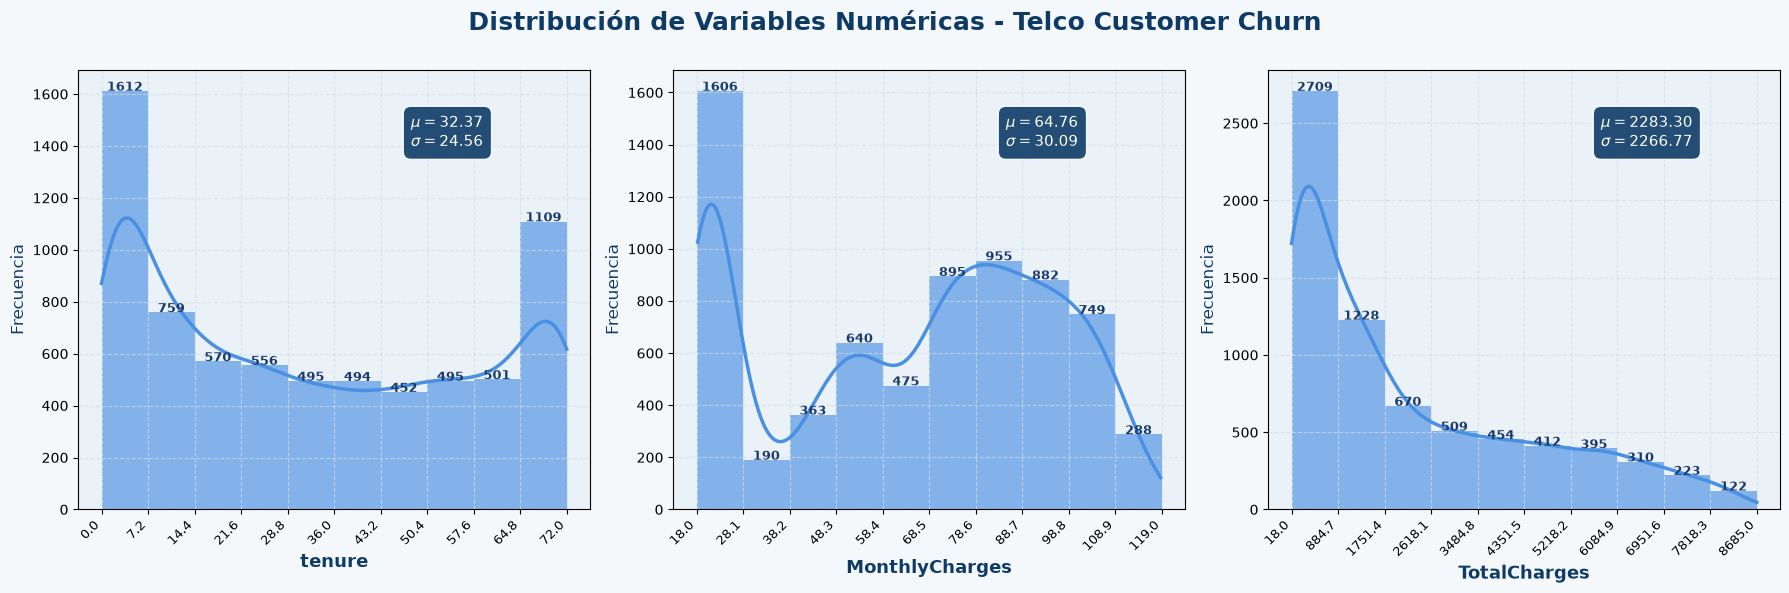

In [20]:
caracteristicas_continuas = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Filtrar características continuas para el análisis univariado
df_continuas = df[caracteristicas_continuas]

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))
for i, col in enumerate(df_continuas.columns):
    # Se añade dropna() preventivo, ya que TotalCharges suele tener valores nulos
    valores, bordes_bins = np.histogram(df_continuas[col].dropna(), range=(np.floor(df_continuas[col].min()), np.ceil(df_continuas[col].max())))
    
    # Gráfico con azul clínico intermedio (#4A90E2) y línea KDE en azul marino profundo (#0D3B66)
    grafico = sns.histplot(data=df_continuas, x=col, bins=bordes_bins, kde=True, ax=ax[i],edgecolor='none', color='#4A90E2', alpha=0.65, line_kws={'lw': 2.5, 'color': '#0D3B66'})
    
    ax[i].set_facecolor('#EBF2F7')
    ax[i].set_xlabel(col, fontsize=13, fontweight='bold', color='#0D3B66')
    ax[i].set_ylabel('Frecuencia', fontsize=12, color='#0D3B66')
    ax[i].set_xticks(np.round(bordes_bins, 1))
    ax[i].set_xticklabels(ax[i].get_xticks(), rotation=45, ha='right', fontsize=9)
    ax[i].grid(True, color='#D0DEE9', linestyle='--', alpha=0.7)
    
    # Anotaciones de frecuencia sobre cada barra
    for j, p in enumerate(grafico.patches):
        altura = p.get_height()
        if altura > 0:
            ax[i].annotate(f'{int(altura)}', (p.get_x() + p.get_width() / 2, altura + 0.8),ha='center', fontsize=9, fontweight='bold',color='#1B3B6F')
    
    # Cuadro de estadísticas (media y desviación estándar) en tono azul marino clínico
    texto_estadisticas = '\n'.join((r'$\mu=%.2f$' % df_continuas[col].mean(),r'$\sigma=%.2f$' % df_continuas[col].std()))
    ax[i].text(0.65, 0.90,texto_estadisticas, transform=ax[i].transAxes, fontsize=11, verticalalignment='top',color='white', bbox=dict(boxstyle='round,pad=0.5', facecolor='#0D3B66', edgecolor='white', alpha=0.9))

fig.patch.set_facecolor('#F4F8FA')
# Título adaptado al contexto del churn
plt.suptitle('Distribución de Variables Numéricas - Telco Customer Churn', fontsize=18, fontweight='bold', color='#0D3B66')
plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.show()

#### **Análisis univariado de variables categóricas**

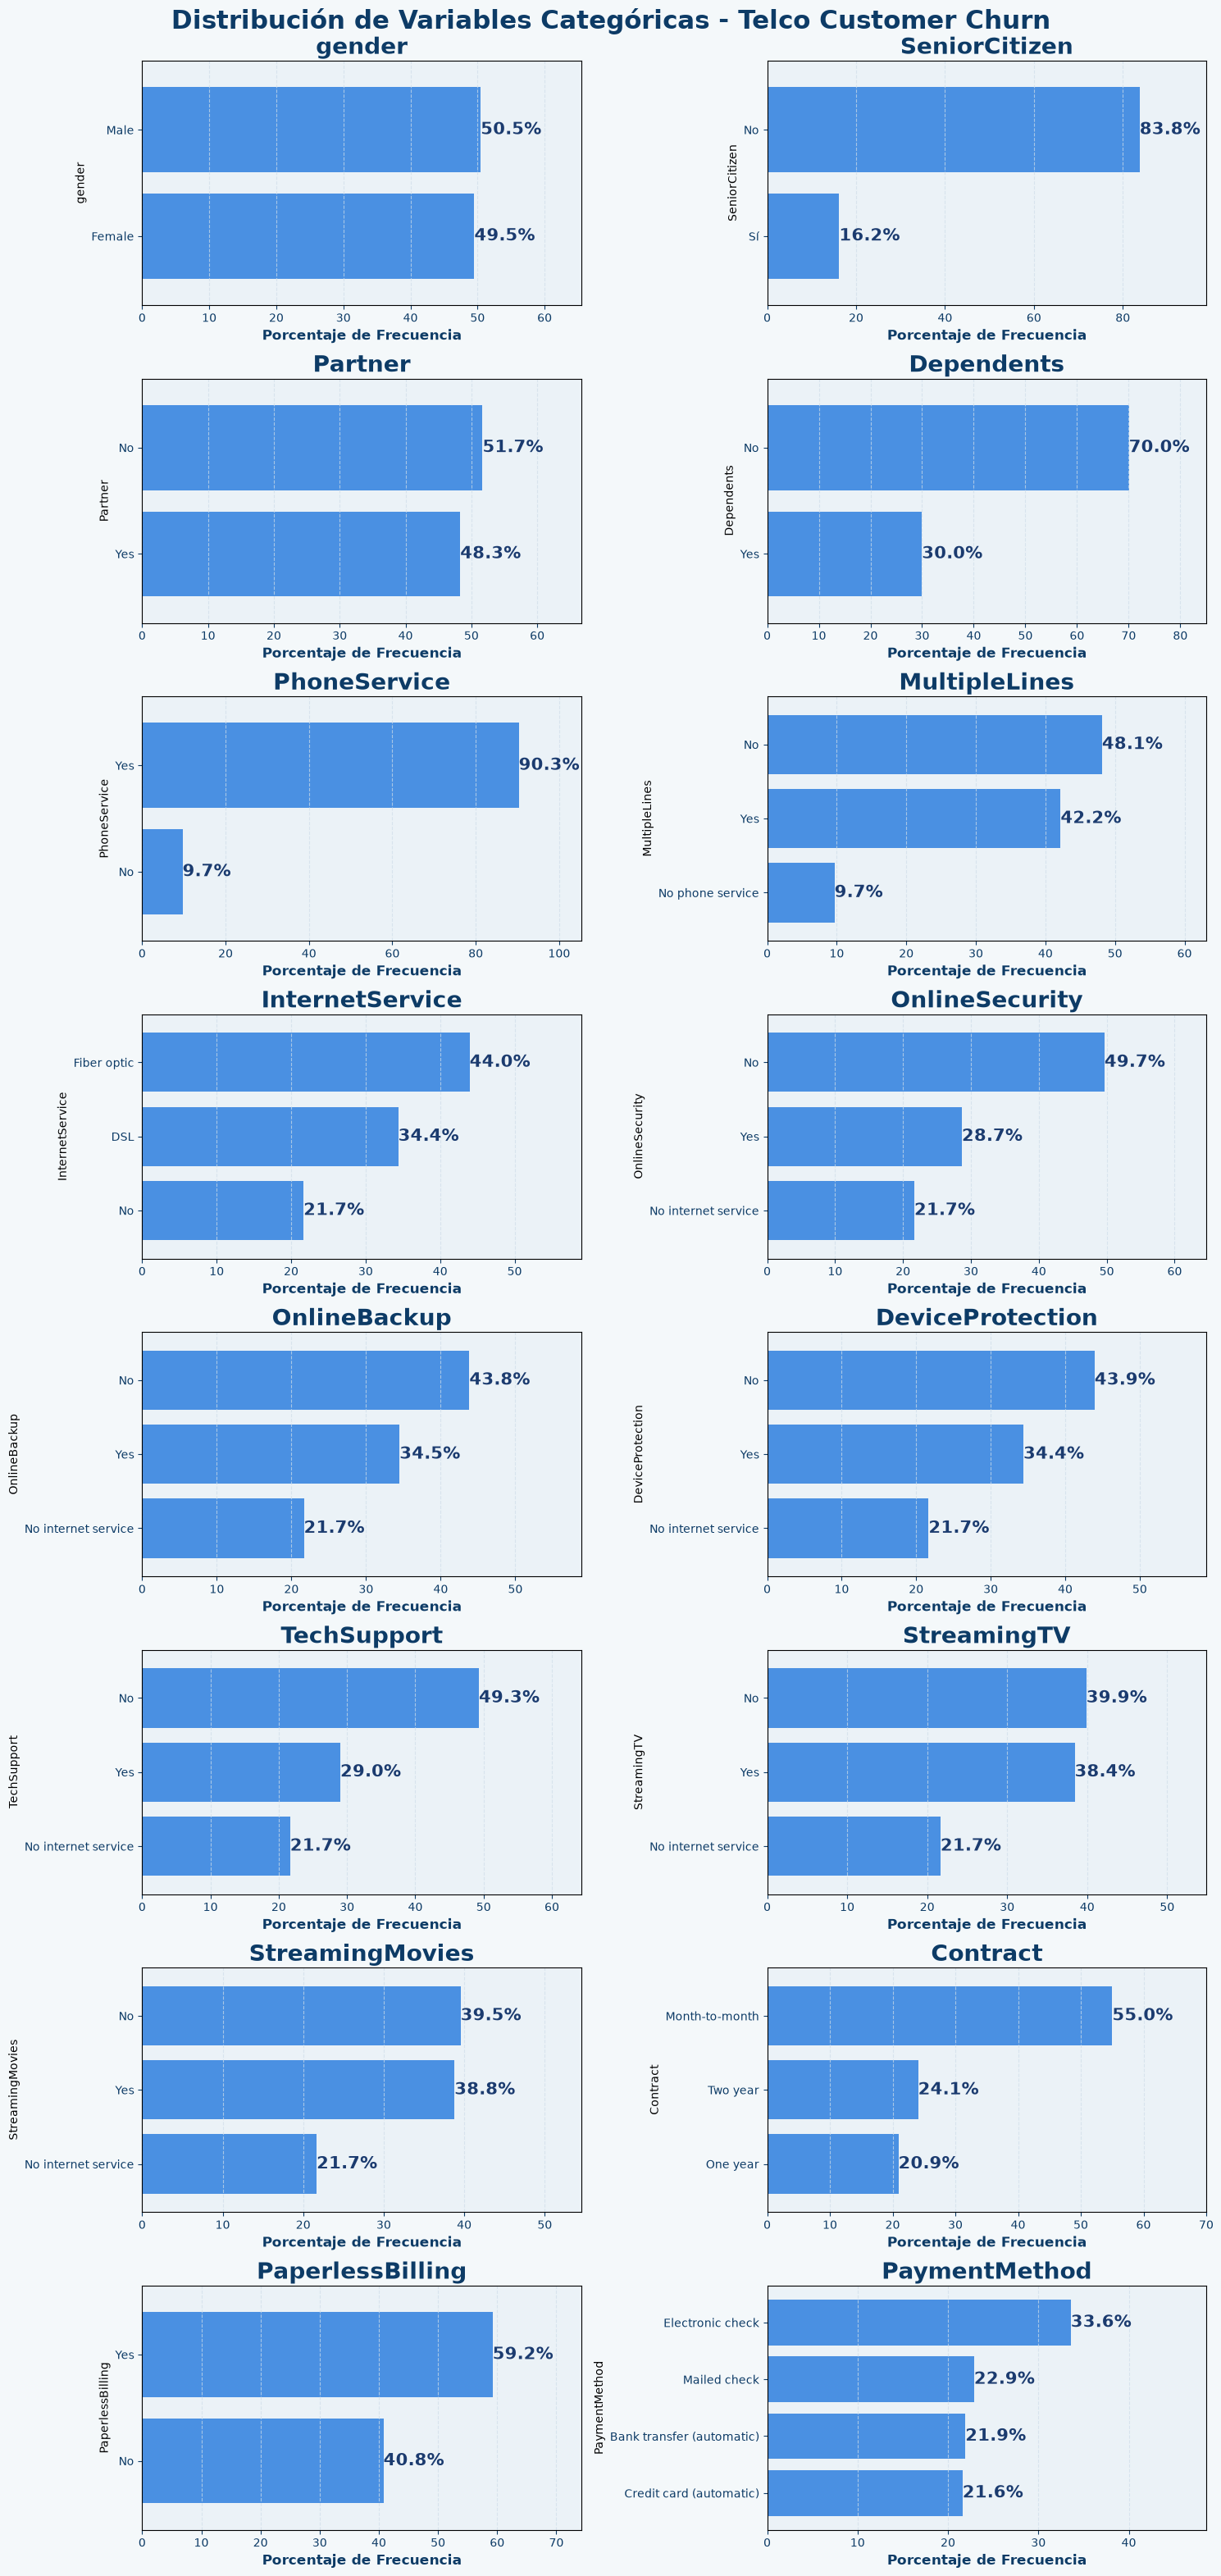

In [21]:
caracteristicas_categoricas = df.select_dtypes(include=['object', 'string']).columns.drop(['customerID_Hash', 'Churn'], errors = 'ignore')
df_categoricas = df[caracteristicas_categoricas].copy()

ncols = 2
nrows = (len(caracteristicas_categoricas) + ncols - 1) // ncols

fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 4 * nrows))
fig.patch.set_facecolor('#F4F8FA')

for i, col in enumerate(caracteristicas_categoricas):
    row = i // ncols
    col_idx = i % ncols
    
    # Calcular porcentajes de frecuencia
    conteo_valores = df[col].value_counts(normalize=True).mul(100).sort_values()
    
    # Graficar gráfico de barras
    conteo_valores.plot(kind='barh', ax=ax[row, col_idx], width=0.8, color='#4A90E2')
    
    # Configurar color de fondo del gráfico y la cuadrícula
    ax[row, col_idx].set_facecolor('#EBF2F7')
    ax[row, col_idx].grid(True, color='#D0DEE9', linestyle='--', alpha=0.7, axis='x')
    
    # Añadir porcentajes de frecuencia a las barras
    for index, value in enumerate(conteo_valores):
        ax[row, col_idx].text(value, index, str(round(value, 1)) + '%', fontsize=15, weight='bold', va='center', color='#1B3B6F')
    
    ax[row, col_idx].set_xlim([0, conteo_valores.max() + 15]) 
    ax[row, col_idx].set_xlabel('Porcentaje de Frecuencia', fontsize=12, fontweight='bold', color='#0D3B66')
    ax[row, col_idx].set_title(f'{col}', fontsize=20, fontweight='bold', color='#0D3B66')
    ax[row, col_idx].tick_params(colors='#0D3B66')

for j in range(len(caracteristicas_categoricas), nrows * ncols):
    r = j // ncols
    c = j % ncols
    ax[r, c].axis('off')

plt.suptitle('Distribución de Variables Categóricas - Telco Customer Churn', fontsize=22, fontweight='bold', color='#0D3B66')
plt.tight_layout()
plt.subplots_adjust(top=0.96)
plt.show()

### **1.5.3 Análisis Bivariado**

#### **Características numéricas vs. Objetivo**

Para las variables numéricas, se calculan y grafican las funciones de estimación de densidad de kernel (KDE).

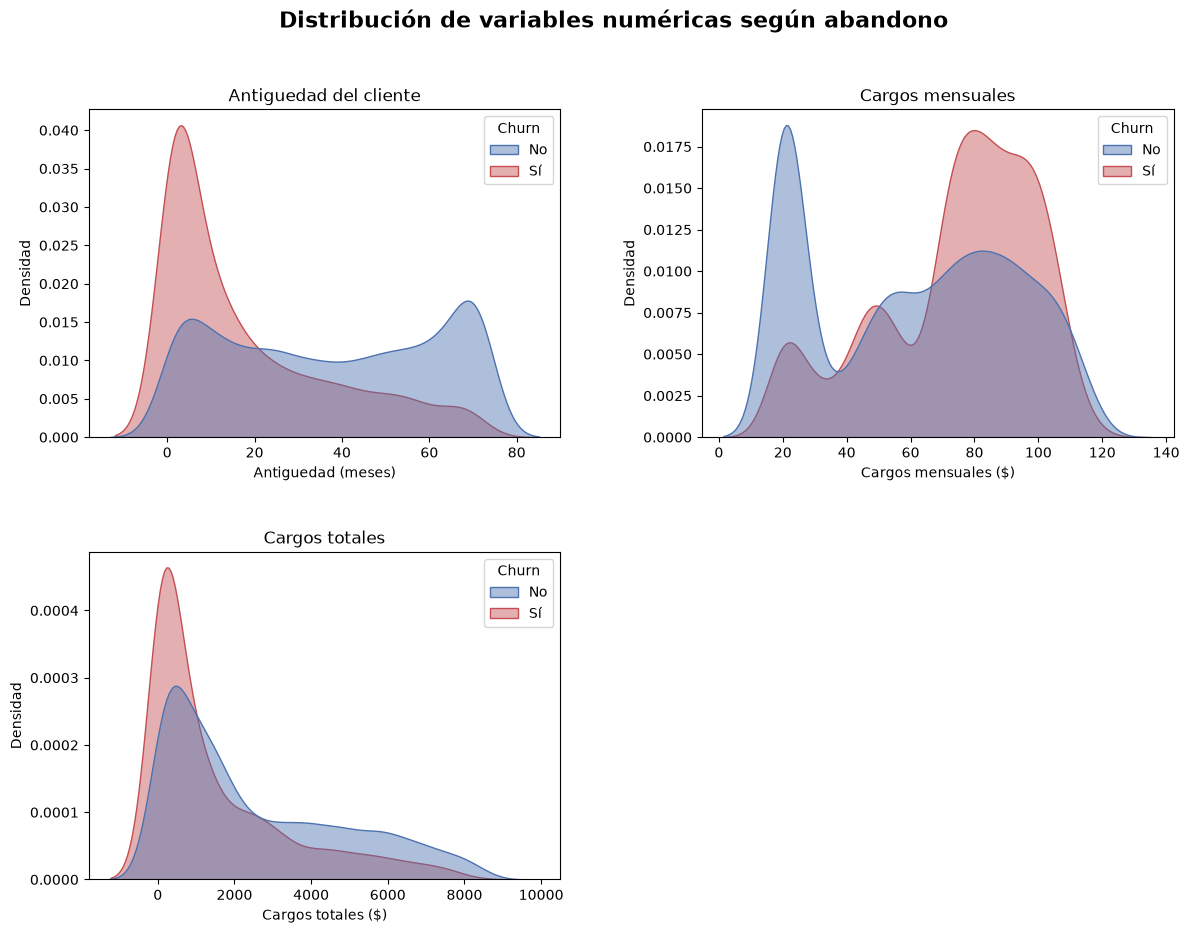

In [22]:
# generar curvas de densidad según la variable Churn
fig, axes = visualizaciones.graficar_curvas_densidad_churn(df)
plt.show()

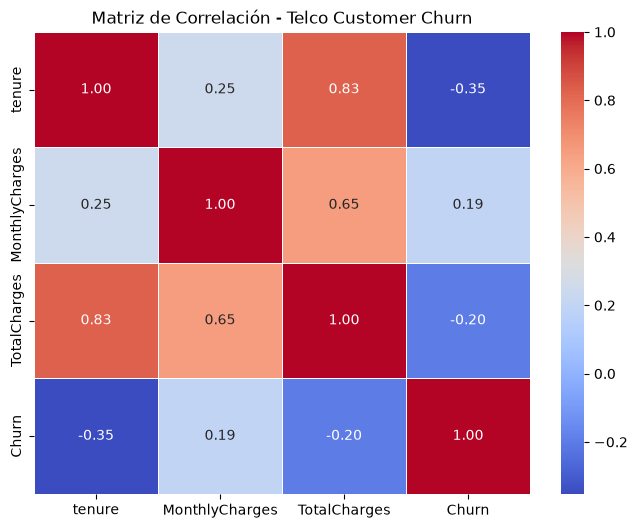

In [23]:
# mapa de calor matriz de correlaciones variables numéricas
df_copy = df.copy()
df_copy["Churn"] = df_copy["Churn"].map({"No": 0, "Yes": 1}).astype(object)
df_copy["Churn"] = pd.to_numeric(df_copy["Churn"], errors="coerce")
numeric_df = df_copy.select_dtypes(include=[np.number])
numeric_df = numeric_df.drop(columns=['customerID_Hash'], errors='ignore')
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlación - Telco Customer Churn')
plt.show()

* **Antiguedad y Cargos Totales (0,825):** Fuerte correlación positiva. Como es lógico, los clientes que llevan más tiempo en la empresa acumulan un gasto total mayor.

* **Antiguedad y Cargos Mensuales (0,248):** Correlación positiva débil. Existe una ligera tendencia donde los clientes más antiguos asumen tarifas mensuales un poco más altas, lo que sugiere que podrían estar contratando servicios de mayor precio.

In [24]:
# agrupar por 'Churn' y calcular el promedio
resumen = df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].mean().round(2)
tabla_churn_numeric = resumen.T
tabla_churn_numeric.columns = ['Churn = No', 'Churn = Sí']
tabla_churn_numeric

,Churn = No,Churn = Sí
tenure,37.57,17.98
MonthlyCharges,61.27,74.44
TotalCharges,2555.34,1531.80


**Observaciones:**

**Antiguedad (Meses):**

* Los clientes activos tienen una antiguedad promedio de 37,57 meses.
* Quienes cancelaron el servicio muestran una permanencia menor, con un promedio de 17,98 meses.
* Los clientes que permanecen en la compañía presentan una antigüedad promedio considerablemente mayor que aquellos que abandonan el servicio.
* Los clientes nuevos con poca antiguedad tienen más probabilidades de cambiar de compañía.

**Cargos Mensuales:**

* El pago mensual promedio de los clientes activos es de $61,27.
* Quienes se dieron de baja pagaban una tarifa un poco mayor, cercana a los $74,44.
* Los clientes que abandonaron el servicio presentan cargos mensuales promedio superiores a los de aquellos que permanecen en la compañía.

**Cargos Totales:**

* Los clientes que mantienen su suscripción acumulan un promedio de $2554,77 en cargos totales.
* Quienes cancelaron el servicio acumularon un gasto inferior, de alrededor de $1531,80.
* Los usuarios con un mayor gasto total acumulado en el tiempo son más propensos a quedarse en la empresa.

#### **Características categóricas vs. Objetivo**

Para las variables categóricas, los gráficos de barras muestran las diferencias entre los grupos objetivo.

##### **Información de Clientes**

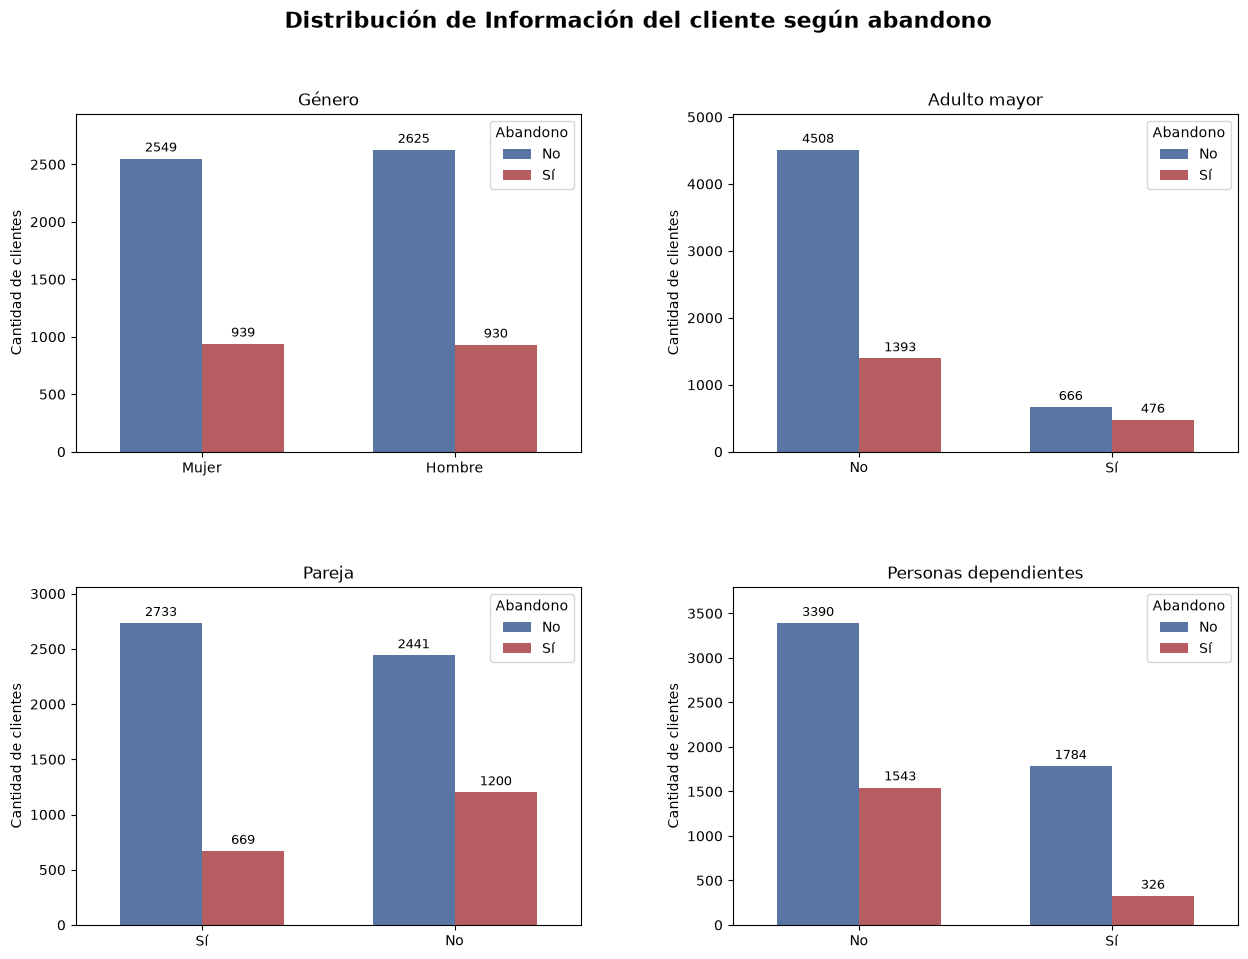

In [25]:
figura_cliente = visualizaciones.graficar_grupo_categorico_churn(
    df,
    nombre_grupo="Información del cliente",
)
display(figura_cliente)
plt.close(figura_cliente)

* La cantidad de cancelaciones es muy similar entre clientes hombres y mujeres, sin presentar una diferencia importante.
* Clientes sin pareja y clientes sin familiares (dependientes), así como los adultos mayores en proporción tiene mayor probabilidad de abandono.
* Los clientes adultos mayores presentan una tasa de abandono superior a la de los clientes que no pertenecen a este grupo.

##### **Servicios Contratados**

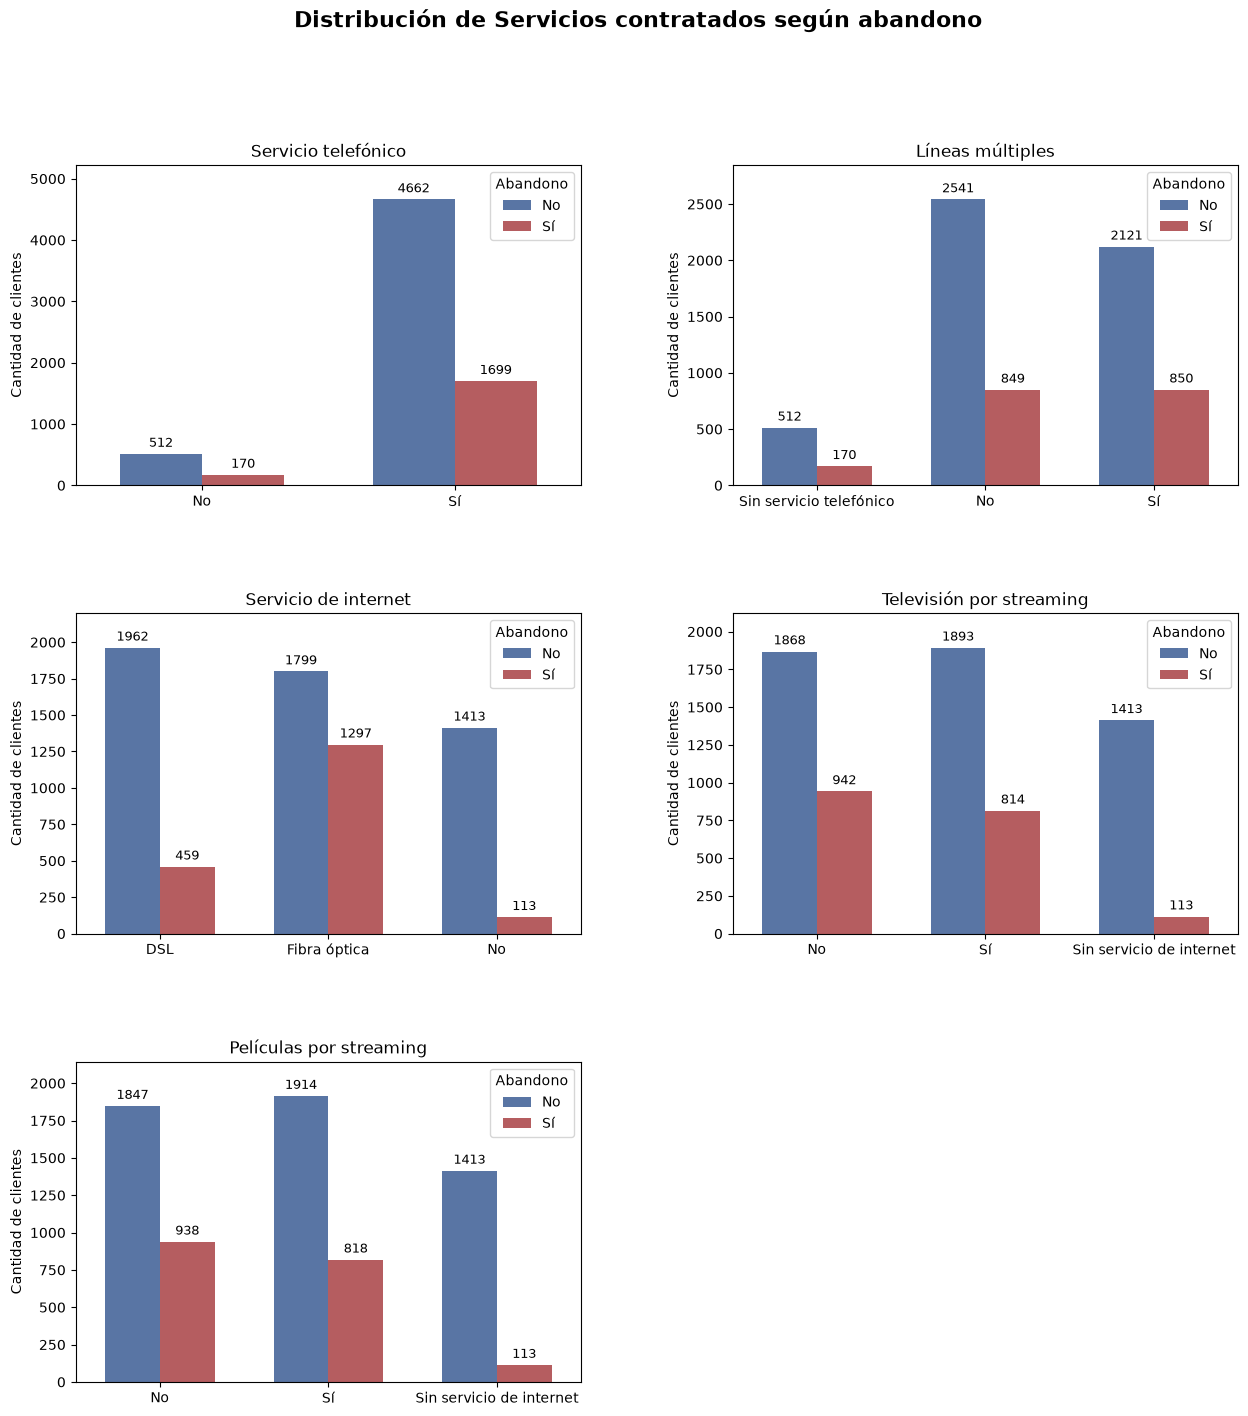

In [26]:
figura_servicios = visualizaciones.graficar_grupo_categorico_churn(
    df,
    nombre_grupo="Servicios contratados"
)
display(figura_servicios)
plt.close(figura_servicios)

* Un alto número de clientes con internet de fibra óptica cancelaron su servicio.
* Los usuarios con conexión DSL abandonan la compañía con menor frecuencia.
* Los clientes que no cuentan con servicio de internet presentan una tasa de abandono muy baja.
* Una gran parte de los clientes elige el servicio de fibra óptica, pero presentan una alta tasa de abandono, lo que sugiere una posible insatisfacción con este tipo de conexión.

##### **Seguridad y soporte**

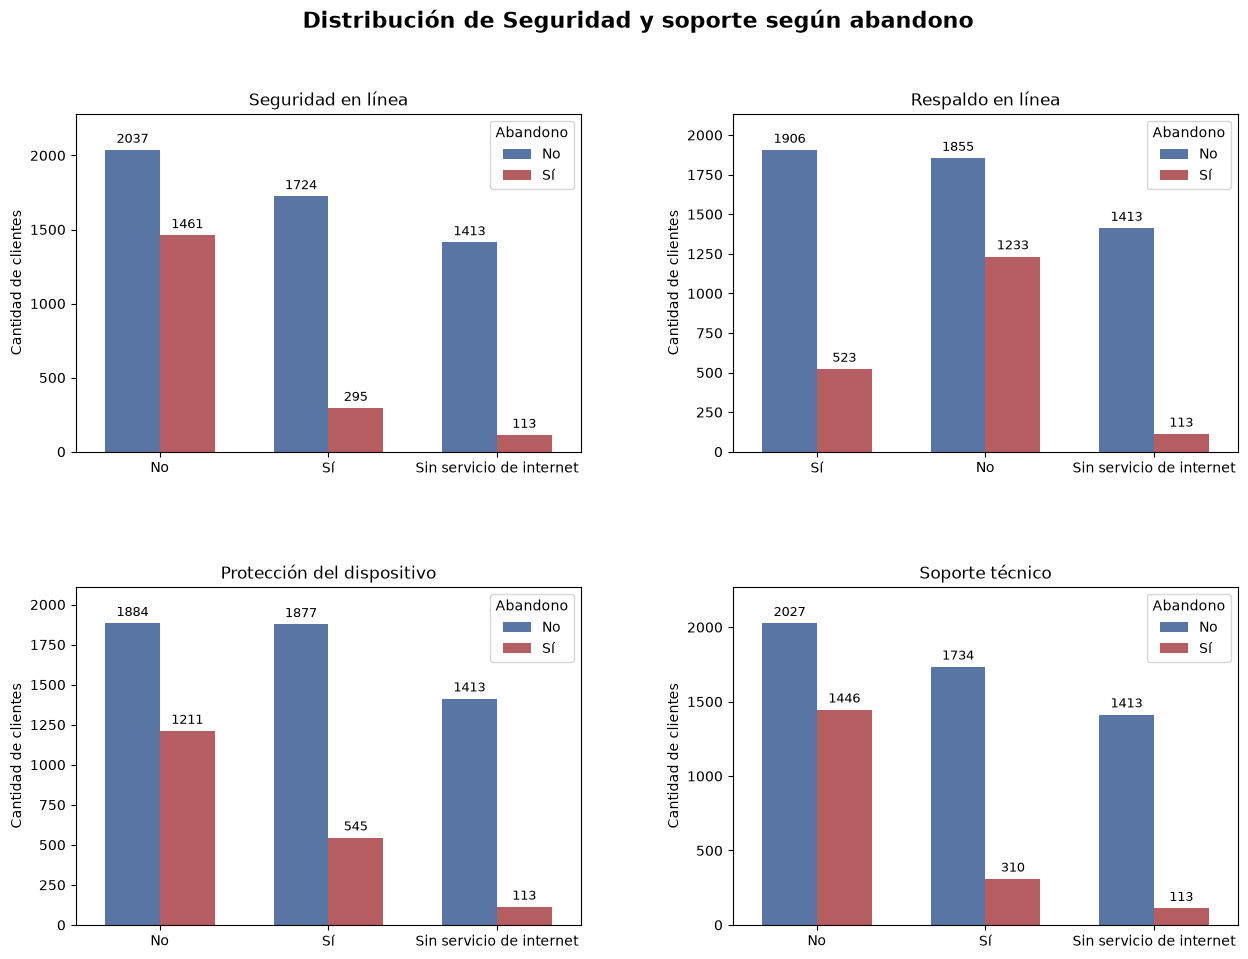

In [27]:
figura_seguridad = visualizaciones.graficar_grupo_categorico_churn(
    df,
    nombre_grupo="Seguridad y soporte"
)
display(figura_seguridad)
plt.close(figura_seguridad)

* Seguridad en línea y Soporte técnico son los servicios que más protegen la retención, bajando el abandono de un 42% (clientes sin el servicio) a solo un 15% (clientes con el servicio).
* Respaldo y Protección del dispositivo también muestran un impacto positivo logrando reducir el nivel de fuga de un 40% a un 22%.
* Los clientes que contrataron servicios de seguridad o soporte técnico adicional tienen menos probabilidades de cancelar su servicio. Resulta clave ofrecer promociones que incluyan seguridad o soporte técnico.

##### **Información de Pago**

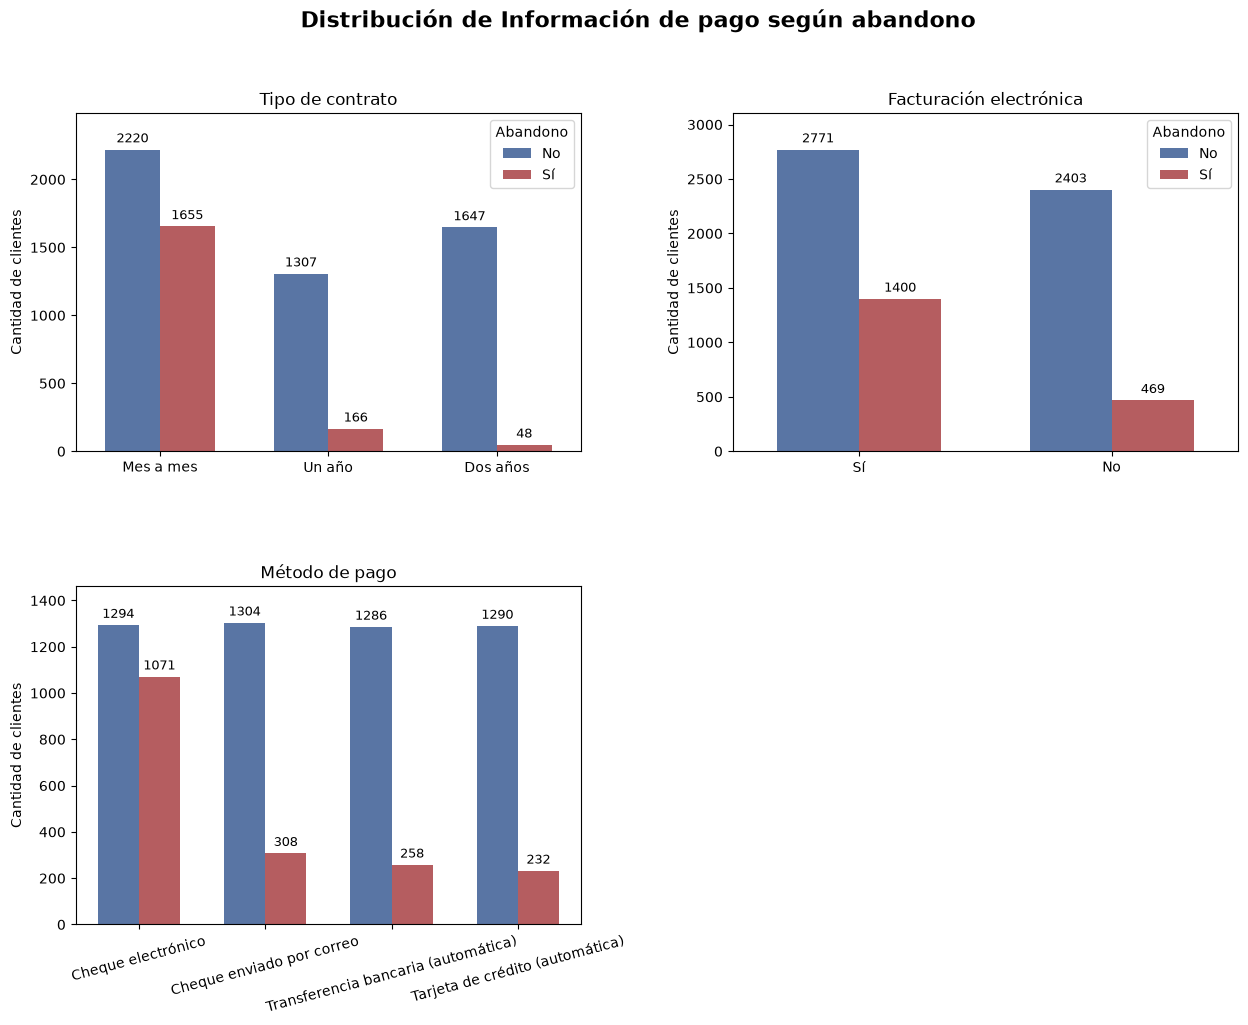

In [28]:
figura_pago = visualizaciones.graficar_grupo_categorico_churn(
    df,
    nombre_grupo="Información de pago"
)
display(figura_pago)
plt.close(figura_pago)

* El abandono es crítico en la modalidad "Mes a mes" (42.7%), pero disminuye drásticamente en compromisos de "Un año" (11.2%) y "Dos años" (2.8%).
* Los clientes con facturación electrónica presentan el doble de tasa de abandono (33.5%) que aquellos con facturación tradicional (16.3%).
* El "Cheque electrónico" es el método de mayor riesgo con un 45.2% de fuga, mientras que las otras alternativas promedian un abandono mucho menor (15-19%).


* Es prioritario incentivar contratos largos. Ofrecer beneficios para que los clientes mensuales pasen a planes anuales o de dos años, donde la tasa de abandono es casi nula.
* Se sugiere revisar el cheque electrónico. Es importante investigar por qué este método genera tantas cancelaciones y sugerir activamente a los clientes que cambien al pago automático.
* Se debe fidelizar al cliente digital. Ya que la facturación electrónica facilita la cancelación, necesitamos buscar nuevas formas de recordarles el valor del servicio para que decidan quedarse.



##### **Correlaciones de variables categóricas con Churn**

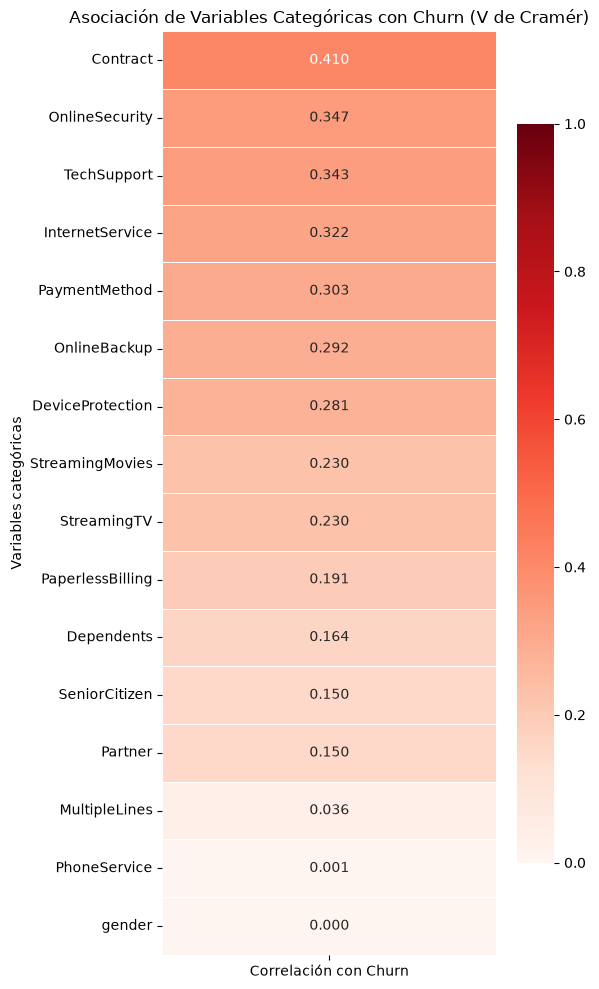

In [29]:
# Identificar las columnas categóricas
cat_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()

# Excluir las columnas que no se utilizarán en la codificación
for col in ['customerID_Hash', 'Churn']:
    if col in cat_cols:
        cat_cols.remove(col)

def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    if min(tabla.shape) < 2:
        return np.nan
    chi2 = ss.chi2_contingency(
        tabla,
        correction=False
    )[0]
    n = tabla.to_numpy().sum()
    if n <= 1:
        return np.nan
    r, k = tabla.shape
    phi2 = chi2 / n
    phi2corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    min_denom = min(kcorr - 1, rcorr - 1)
    if min_denom <= 0:
        return np.nan
    return np.sqrt(phi2corr / min_denom)

churn_corr = {}
for col in cat_cols:
    churn_corr[col] = cramers_v(df[col], df['Churn'])

corr_df = pd.DataFrame.from_dict(churn_corr, orient='index', columns=['Correlación con Churn'])
corr_df = corr_df.sort_values(by='Correlación con Churn', ascending=False)

plt.figure(figsize=(6, 10))
sns.heatmap(
    corr_df, 
    annot=True, 
    cmap='Reds',      # Escala de rojos para advertir riesgo de abandono
    fmt=".3f", 
    linewidths=.5, 
    vmin=0, 
    vmax=1,         # Ajustar el máximo a 1 resalta el contraste del bloque superior
    cbar_kws={"shrink": .8}
)
plt.title("Asociación de Variables Categóricas con Churn (V de Cramér)")
plt.ylabel("Variables categóricas")
plt.tight_layout()
plt.show()

### **1.5.4 Algoritomos Evaluados**

#### **Criterios para la selección de algoritmos**

La selección de los algoritmos se realizó de acuerdo con el objetivo de cada tarea, considerando el tipo de variable que se busca predecir o analizar, las características de los datos y la posibilidad de comparar métodos con distintos enfoques.

**Clasificación:** El objetivo es predecir si un cliente abandonará el servicio (`Churn`). Por tratarse de una variable con dos categorías, se seleccionaron algoritmos capaces de resolver problemas de clasificación binaria. La Regresión Logística se utilizó como referencia por su enfoque lineal y facilidad de interpretación, mientras que SVM permite evaluar un método basado en la separación entre clases. El Árbol de Decisión se incluyó por su estructura interpretable. Finalmente, Random Forest y XGBoost se seleccionaron para comparar modelos de ensamble: el primero combina varios árboles para reducir la variabilidad de las predicciones, mientras que el segundo los construye de forma secuencial, buscando corregir los errores de los anteriores.

**Regresión:** El objetivo es estimar la antigüedad del cliente (`tenure`), que corresponde a una variable numérica. Se seleccionaron Regresión Lineal y Árbol de Decisión para comparar dos enfoques: uno que representa relaciones lineales entre las variables y otro que puede identificar relaciones no lineales. El criterio principal fue evaluar qué tan bien cada método estima valores continuos a partir de las características de los clientes.

**Segmentación:** A diferencia de las tareas anteriores, aquí no existe una variable objetivo que se deba predecir. El propósito es agrupar clientes según sus características y similitud. Por este motivo, se seleccionó K-Means, un algoritmo que forma grupos a partir de las distancias entre los datos y los centros de cada grupo. Para determinar una cantidad adecuada de grupos, se consideraron la variación interna de los grupos (inercia) y el índice *Silhouette*, que permite evaluar qué tan bien separados se encuentran.

En conjunto, esta selección permite comparar métodos con distintos enfoques y definir las transformaciones necesarias para cada tarea, ya que los algoritmos no trabajan todos de la misma manera con los datos.

# **2. Preparación de los Datos para Machine Learning**

## **2.1 Análisis de Completitud**

In [30]:
# conteo de valores nulos por columna
df.isnull().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
customerID_Hash      0
dtype: int64

* La columna **TotalCharges** tienen algunos valores faltantes

In [31]:
# muestra registros con valores nulos en TotalCharges
df[np.isnan(df['TotalCharges'])]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,customerID_Hash
488,Female,No,Yes,Yes,0,No,No phone service,DSL,Yes,No,...,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No,3fc827a9c771a5597e1b9563ba46bd77b5a33daad5f094...
753,Male,No,No,Yes,0,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No,cc8dcc067e61d7292f35e1d99cf280c8f1663b1d6b9dc0...
936,Female,No,Yes,Yes,0,Yes,No,DSL,Yes,Yes,...,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No,58d283200bed248b5d1e0eb621b905ecbb502854900fb3...
1082,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No,ea0b24cc08647ff604fd33a68453a8adb51fdc83f96386...
1340,Female,No,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,...,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No,0e9341d2f088bdb7928f46db857c21c35c9eaafb56084d...
3331,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No,8c6c0d363aa75ea0795734b32d5adcbbd77845674cc04e...
3826,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No,f3d447e5d65b5d31443dae3b897268f29b906c53a3bb29...
4380,Female,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No,3c63ffbaff09f452804dc16726922dfddfb6354320fd79...
5218,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No,01b32519075edcfd0f091c271f6cc693e2ed154b5a38c9...
6670,Female,No,Yes,Yes,0,Yes,Yes,DSL,No,Yes,...,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No,53819de429be29e2cf2d830bf81fd95987cea3db3612ce...


* En los registros donde **TotalCharges** presenta valores nulos, la antiguedad del cliente (**tenure**) es igual a 0. Por este motivo, y dado que la baja cantidad de valores faltantes no afectará la calidad del conjunto, es seguro reemplazar dichos valores faltantes por 0

In [32]:
# reemplazar valores nulos de TotalCharges por 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Valores nulos de TotalCharges reemplazados por 0.")

Valores nulos de TotalCharges reemplazados por 0.


## **2.2 Análisis de Duplicidad**

In [33]:
# registros duplicados
print(f"Cantidad de registros duplicados: {df.duplicated().sum()}")

Cantidad de registros duplicados: 0


* Tras la revisión, no se encontraron valores duplicados en el conjunto de datos

## **2.3 Análisis de valores atípicos**

In [34]:
# buscar valores atípicos usando el rango intercuartil
columnas_numericas = ["tenure", "MonthlyCharges", "TotalCharges"]

for columna in columnas_numericas:
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)
    rango_intercuartil = q3 - q1

    limite_inferior = q1 - 1.5 * rango_intercuartil
    limite_superior = q3 + 1.5 * rango_intercuartil

    valores_atipicos = df[
        (df[columna] < limite_inferior) | (df[columna] > limite_superior)
    ]

    if len(valores_atipicos) > 0:
        print(f"{columna}: sí presenta valores atípicos ({len(valores_atipicos)} registros).")
    else:
        print(f"{columna}: no presenta valores atípicos.")

tenure: no presenta valores atípicos.
MonthlyCharges: no presenta valores atípicos.
TotalCharges: no presenta valores atípicos.


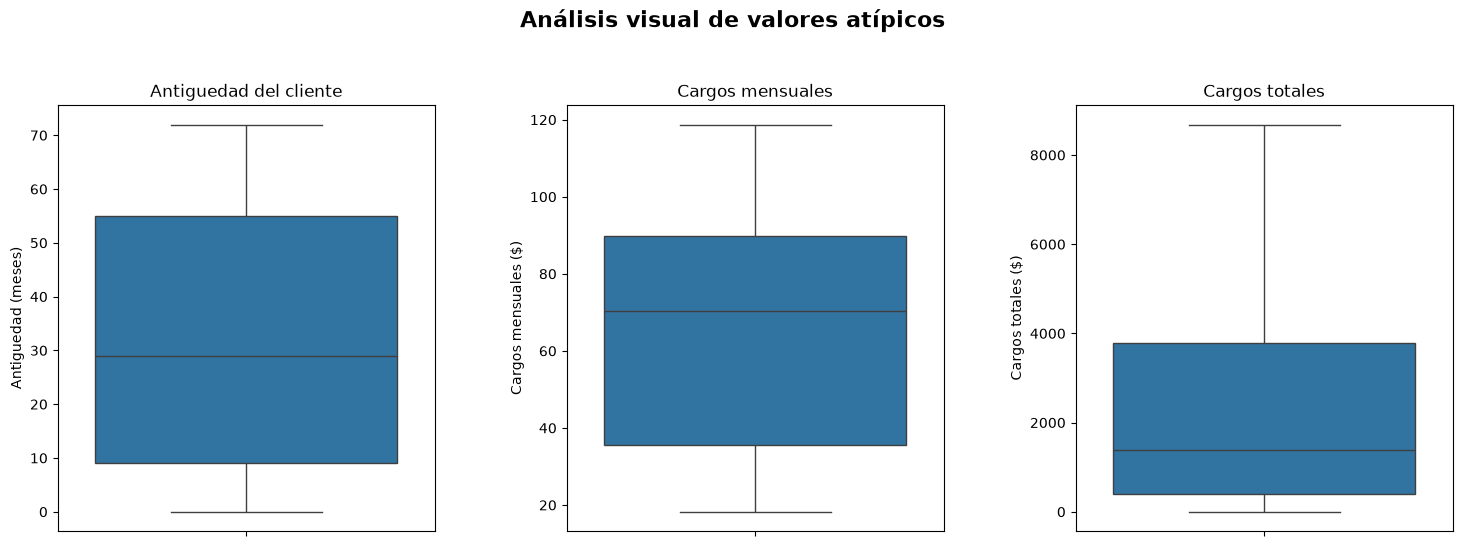

In [35]:
# crear una figura con múltiples espacios
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Análisis visual de valores atípicos", fontsize=16, fontweight="bold")

# dibujar cada gráfico de caja con nombres descriptivos en español
sns.boxplot(y=df["tenure"], ax=axes[0])
axes[0].set_title("Antiguedad del cliente")
axes[0].set_xlabel("")
axes[0].set_ylabel("Antiguedad (meses)")

sns.boxplot(y=df["MonthlyCharges"], ax=axes[1])
axes[1].set_title("Cargos mensuales")
axes[1].set_xlabel("")
axes[1].set_ylabel("Cargos mensuales ($)")

sns.boxplot(y=df["TotalCharges"], ax=axes[2])
axes[2].set_title("Cargos totales")
axes[2].set_xlabel("")
axes[2].set_ylabel("Cargos totales ($)")

plt.subplots_adjust(wspace=0.35, top=0.82)
plt.show()

* No se encontraron valores atípicos en las variables numéricas analizadas

## **2.4 Codificación de características categóricas**

**Decisión sobre la codificación One-Hot:**

Con base en la naturaleza de las variables categóricas del dataset Telco Customer Churn, se evaluará la aplicación de codificación según las características que representan:

1. **Variables nominales:** No tienen un orden definido entre sus categorías. Se recomienda aplicar One-Hot Encoding para evitar que los modelos interpreten una jerarquía inexistente.
2. **Variables binarias:** Poseen únicamente dos categorías posibles, por lo que pueden representarse mediante valores numéricos (0 y 1), sin necesidad de aplicar One-Hot Encoding.
3. **Variables ordinales:** Tienen un orden inherente entre sus categorías, por lo que pueden representarse mediante una codificación ordinal que conserve dicha jerarquía.

Según estos criterios:

- `gender`: Variable binaria que representa el género del cliente (Female y Male). Se puede representar mediante codificación binaria.
- `SeniorCitizen`: Variable binaria que indica si el cliente es adulto mayor (No y Sí). Se puede representar mediante codificación binaria.
- `Partner`: Variable binaria que indica si el cliente tiene pareja (Yes y No). Se utilizará codificación binaria.
- `Dependents`: Variable binaria que indica si el cliente tiene personas dependientes (Yes y No). Se utilizará codificación binaria.
- `PhoneService`: Variable binaria que indica si el cliente tiene contratado servicio telefónico (Yes y No). Se utilizará codificación binaria.
- `PaperlessBilling`: Variable binaria que indica si el cliente utiliza facturación electrónica (Yes y No). Se utilizará codificación binaria.
- `MultipleLines`: Variable nominal que representa la disponibilidad de múltiples líneas telefónicas (Yes, No y No phone service). Se aplicará One-Hot Encoding.
- `InternetService`: Variable nominal que representa el tipo de conexión a Internet (DSL, Fiber optic y No). Se aplicará One-Hot Encoding.
- `OnlineSecurity`: Variable nominal que indica si el cliente tiene contratado el servicio de seguridad en línea (Yes, No y No internet service). Se aplicará One-Hot Encoding.
- `OnlineBackup`: Variable nominal que indica si el cliente tiene contratado el servicio de respaldo en línea (Yes, No y No internet service). Se aplicará One-Hot Encoding.
- `DeviceProtection`: Variable nominal que indica si el cliente tiene contratado el servicio de protección de dispositivos (Yes, No y No internet service). Se aplicará One-Hot Encoding.
- `TechSupport`: Variable nominal que indica si el cliente tiene contratado soporte técnico (Yes, No y No internet service). Se aplicará One-Hot Encoding.
- `StreamingTV`: Variable nominal que indica si el cliente tiene contratado televisión por streaming (Yes, No y No internet service). Se aplicará One-Hot Encoding.
- `StreamingMovies`: Variable nominal que indica si el cliente tiene contratado películas por streaming (Yes, No y No internet service). Se aplicará One-Hot Encoding.
- `PaymentMethod`: Variable nominal que representa el método de pago utilizado (Electronic check, Mailed check, Bank transfer (automatic) y Credit card (automatic)). Se aplicará One-Hot Encoding.
- `Contract`: Variable ordinal que representa el tipo de contrato (Month-to-month < One year < Two year). Se utilizará codificación ordinal para conservar la jerarquía entre sus categorías.
- `Churn`: Variable objetivo binaria que indica si el cliente abandonó la empresa (Yes y No). Se transformará a valores numéricos (1 y 0) exclusivamente para los modelos de clasificación.

**Resumen:**

- **Necesitan codificación One-Hot:** `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `PaymentMethod`.
- **Necesitan codificación binaria:** `gender`, `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`.
- **Necesitan codificación ordinal:** `Contract`.
- **Ya se encuentran codificadas numéricamente:** `SeniorCitizen`.
- **Variable objetivo:** `Churn`, codificada como 0 y 1 exclusivamente para clasificación.

## **2.5 Evaluación del Escalado de Características**

El escalado de características ajusta la magnitud de las variables numéricas para que tengan escalas comparables. Su aplicación depende de los algoritmos utilizados.

**Decisión sobre el escalado:**

Los modelos utilizados presentan diferentes necesidades respecto al escalado:

- **Regresión Logística y SVM:** Se aplicará MinMaxScaler para llevar las variables numéricas a un rango común, ya que estos algoritmos son sensibles a las diferencias de escala.
- **Regresión Lineal:** Se aplicará MinMaxScaler para mantener las variables numéricas en escalas comparables, aunque este algoritmo no requiere necesariamente escalamiento para realizar sus predicciones.
- **K-Means:** Se aplicará MinMaxScaler porque utiliza distancias euclidianas para agrupar las observaciones, por lo que las diferencias de magnitud entre las variables pueden afectar la formación de los clusters.
- **Árboles de Decisión y modelos de ensamble basados en árboles:** Se omitirá el escalado, ya que realizan divisiones mediante umbrales y, por lo general, no son sensibles a las diferencias de escala de las variables.

**En consecuencia**, no se realizará un escalado global del dataset. Las transformaciones se aplicarán mediante pipelines de preprocesamiento específicos para cada modelo, según sus necesidades.

# **3. Construcción y Evaluación de Modelos**

In [36]:
# Crear una copia de referencia del dataset para la implementación de modelos
df_base_modelos = df.copy(deep=True)

# Crear datasets independientes para cada tipo de aprendizaje
df_clasificacion = df_base_modelos.copy(deep=True)
df_regresion = df_base_modelos.copy(deep=True)
df_segmentacion = df_base_modelos.copy(deep=True)

## **3.1 Aprendizaje Supervisado: Modelos de Clasificación**

### **3.1.1 Selección y Conservación de Características**

Construcción de listados para preprocesamiento

In [37]:
# Características numéricas para clasificación
numericas_clf = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges',
    'Aumento_Tarifa',
    'Total_Servicios_Extra'
]

# Características categóricas binarias
categoricas_binarias_clf = [
    'PaperlessBilling',
    'Pago_Automatico',
    'Vive_Solo',
    'Perfil_Alto_Riesgo'
]

# Características categóricas nominales
categoricas_nominales_clf = [
    'InternetService'
]

# Características categóricas ordinales
categoricas_ordinales_clf = [
    'Contract'
]

jerarquia_contrato_clf = [
    ['Month-to-month', 'One year', 'Two year']
]

In [38]:
# Transformar la variable objetivo únicamente en el dataset de clasificación
df_clasificacion["Churn"] = (
    df_clasificacion["Churn"]
    .map({"No": 0, "Yes": 1})
    .astype("int8")
)

* Manipulamos el formato de los valores de la variable objetivo para que el modelo interprete de mejor manera. YES/NO -> 1/0

### **3.1.2 Modelo de Regresión Logística**

*   **Transformaciones específicas:** Usamos el pipeline numérico base (escalamiento con `MinMaxScaler`), paso vital porque este algoritmo es muy sensible a los valores extremos y a las diferencias de escala.
*   **Configuración del modelo:** Aplicamos `LogisticRegression` con clases balanceadas (`class_weight='balanced'`)

#### **Pipelines de Transformación**


Se implementan pipelines de transformación numérica y categórica, se crea un transformador personalizado (`TelcoFeatureEngineer`) para generar variables clave, y se divide el dataset estratificando la variable objetivo (80% entrenamiento / 20% prueba).

In [39]:
pipeline_numerico_clf = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ('scaler', MinMaxScaler())
])

pipeline_categorico_nominal = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False)
    )
])

pipeline_categorico_binario = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

pipeline_categorico_ordinal = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(categories=jerarquia_contrato_clf, handle_unknown='use_encoded_value', unknown_value=-1))
])
    
pipeline_preprocessor = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerico_clf, numericas_clf),
        ("cat_nom", pipeline_categorico_nominal, categoricas_nominales_clf),
        ("cat_bin", pipeline_categorico_binario, categoricas_binarias_clf),
        ("cat_ord", pipeline_categorico_ordinal, categoricas_ordinales_clf)
    ],
    remainder="drop"
)

#### **Pipeline de Modelo LR**

In [40]:
pipeline_final_lr = Pipeline(steps=[
    ('ingenieria_caracteristicas', TelcoFeatureEngineer(drop_original=True, drop_addons=True)),
    ('preprocesador', clone(pipeline_preprocessor)),
    ('modelo', LogisticRegression(
        class_weight='balanced',
        random_state=42
    ))
])

#### **División de los Datos**

In [41]:
# Separar características predictoras y variable objetivo
X_clf = df_clasificacion.drop(
    columns=['Churn', 'customerID_Hash']
)

y_clf = df_clasificacion['Churn']

# División de entrenamiento y prueba
X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf,
    y_clf,
    test_size=0.20,
    stratify=y_clf,
    random_state=42
)

#### **Entrenamiento y Evaluación LR**

In [42]:
pipeline_final_lr.fit(X_clf_train, y_clf_train)

y_pred = pipeline_final_lr.predict(X_clf_test)

reporte = classification_report(y_clf_test, y_pred, output_dict=True)
df_reporte = pd.DataFrame(reporte).transpose().round(3)
display(df_reporte)

,precision,recall,f1-score,support
0,0.902,0.695,0.785,1035.00
1,0.484,0.791,0.600,374.00
accuracy,0.720,0.720,0.720,0.72
macro avg,0.693,0.743,0.693,1409.00
weighted avg,0.791,0.720,0.736,1409.00


El modelo logró una Exactitud del 72%. Como muestran los gráficos generados, identificó correctamente 296 fugas (Verdaderos Positivos), reduciendo los Falsos Negativos a 78 clientes no detectados. A cambio, generó 316 Falsos Positivos. La curva ROC respalda este rendimiento con un AUC de 0.830, demostrando una buena capacidad general para separar las clases.

In [43]:
# Evaluar el modelo en los datos de Entrenamiento
print(classification_report(y_clf_train, pipeline_final_lr.predict(X_clf_train)))

              precision    recall  f1-score   support

           0       0.92      0.71      0.80      4139
           1       0.51      0.82      0.62      1495

    accuracy                           0.74      5634
   macro avg       0.71      0.76      0.71      5634
weighted avg       0.81      0.74      0.75      5634



* No se detecta overfitting.

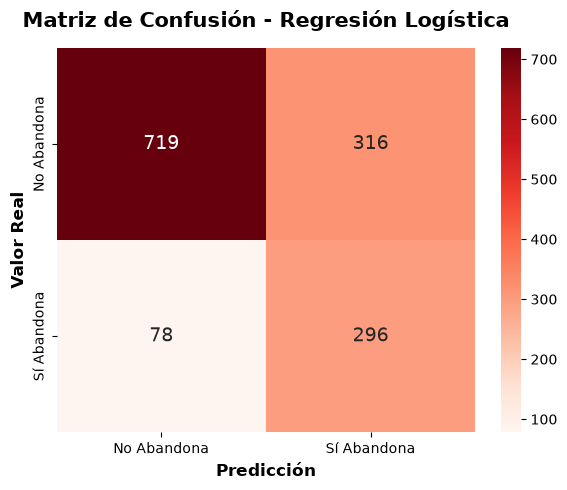

In [44]:
# Graficar Matriz de confusión para modelo de Regresión Logística
plot_matriz_confusion(y_clf_test, y_pred, nombre_modelo="Regresión Logística")

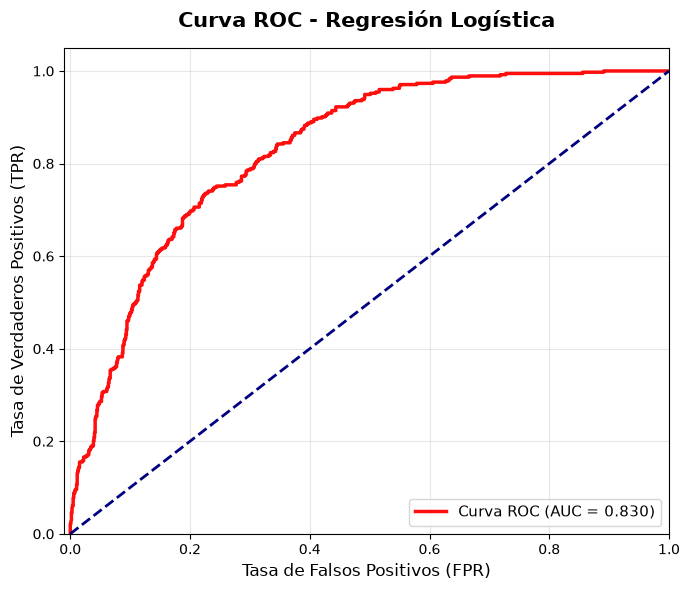

In [45]:
# Grafica Curva ROC para modelo de Regresión Logística
y_test_proba = pipeline_final_lr.predict_proba(X_clf_test)[:, 1]
plot_curva_roc(y_clf_test, y_test_proba, nombre_modelo="Regresión Logística")

### **3.1.3 Modelo de Máquinas de Vectores de Soporte (SVM)**

*   **Transformaciones específicas:** Se incluye el escalamiento numérico (`MinMaxScaler`), obligatorio para SVM porque se basa en calcular distancias.
*   **Configuración del modelo:** Se utiliza `SVC` con kernel radial (RBF) y clases balanceadas. Para obtener probabilidades se incorpora `CalibratedClassifierCV` con calibración sigmoide y validación cruzada de cinco particiones.

#### **Pipeline del Modelo SVM**

In [46]:
# Pipeline base de SVM
pipeline_base_svm = Pipeline(steps=[
    ('ingenieria_caracteristicas',
     TelcoFeatureEngineer(drop_original=True, drop_addons=True)),
    ('preprocesador', clone(pipeline_preprocessor)),
    ('modelo', SVC(kernel='rbf',class_weight='balanced',random_state=42))
])

# Pipeline SVM con calibración de probabilidades
pipeline_final_svm = CalibratedClassifierCV(
    estimator=pipeline_base_svm,
    method='sigmoid',
    cv=5,
    ensemble=False
)

#### **Entrenamiento y Evaluación SVM**

In [47]:
# Entrenamiento y predicción
pipeline_final_svm.fit(X_clf_train, y_clf_train)

y_pred_svm = pipeline_final_svm.predict(X_clf_test)

reporte = classification_report(y_clf_test, y_pred_svm, output_dict=True)
df_reporte = pd.DataFrame(reporte).transpose().round(3)
display(df_reporte)

,precision,recall,f1-score,support
0,0.879,0.783,0.828,1035.000
1,0.539,0.703,0.610,374.000
accuracy,0.762,0.762,0.762,0.762
macro avg,0.709,0.743,0.719,1409.000
weighted avg,0.789,0.762,0.770,1409.000


Obtuvo la Exactitud más alta (76.2%). Sin embargo, la matriz de confusión revela que es peor para la retención: identificó 263 fugas, pero dejó escapar 111 Falsos Negativos (clientes que se van sin ser detectados), sumado a 225 Falsos Positivos. Su AUC de 0.814 confirma que predice bien, pero separa un poco peor las clases que la Regresión Logística.

In [48]:
# Evaluar el modelo en los datos de Entrenamiento
print(classification_report(y_clf_train, pipeline_final_svm.predict(X_clf_train)))

              precision    recall  f1-score   support

           0       0.89      0.79      0.83      4139
           1       0.55      0.72      0.62      1495

    accuracy                           0.77      5634
   macro avg       0.72      0.75      0.73      5634
weighted avg       0.80      0.77      0.78      5634



* No se detecta overfitting.

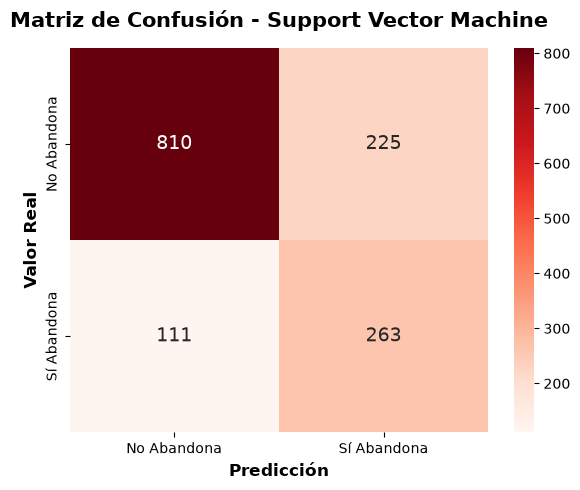

In [49]:
# Visualizaciones
plot_matriz_confusion(y_clf_test, y_pred_svm, nombre_modelo="Support Vector Machine")

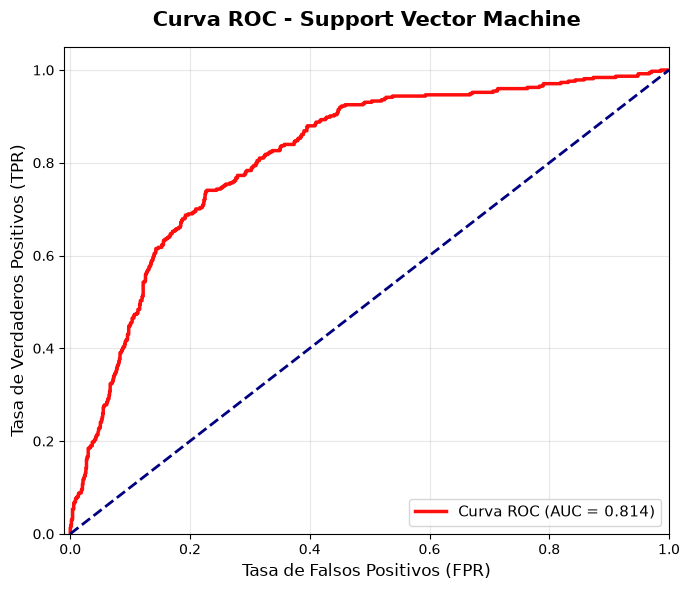

In [50]:
y_proba_svm = pipeline_final_svm.predict_proba(X_clf_test)[:, 1]
plot_curva_roc(y_clf_test, y_proba_svm, nombre_modelo="Support Vector Machine")

### **3.1.3 Modelo de Árbol de Decisión (DecisionTreeClassifier)**

*   **Transformaciones específicas:** Usamos un pipeline independiente que solo rellena nulos (`SimpleImputer`). No se aplicó escalamiento ni manejo de atípicos porque a los árboles (basados en reglas lógicas) no les afecta la escala.
*   **Configuración del modelo:** Se limitó la profundidad a 5 niveles (`max_depth=5`) para evitar el sobreajuste, conservando el peso balanceado.

In [51]:
# pipeline numérico sin escalamiento ni tratamiento de outliers
pipeline_numerico_arbol = Pipeline([
    ("imputer", SimpleImputer(strategy="mean"))
])

pipeline_preprocessor_arbol = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerico_arbol, numericas_clf),
        ("cat_nom", pipeline_categorico_nominal, categoricas_nominales_clf),
        ("cat_bin", pipeline_categorico_binario, categoricas_binarias_clf),
        ("cat_ord", pipeline_categorico_ordinal, categoricas_ordinales_clf)
    ],
    remainder="drop"
)

#### **Pipeline del Modelo DTC**

In [52]:
pipeline_final_dtc = Pipeline(steps=[
    ('ingenieria_caracteristicas', TelcoFeatureEngineer(drop_original=True, drop_addons=True)),
    ('preprocesador', clone(pipeline_preprocessor_arbol)),
    ('modelo', DecisionTreeClassifier(
        class_weight='balanced', 
        max_depth = 5,
        random_state=42
    ))
])

In [53]:
# Entrenamiento y predicción
pipeline_final_dtc.fit(X_clf_train, y_clf_train)

y_pred_dtc = pipeline_final_dtc.predict(X_clf_test)

reporte = classification_report(y_clf_test, y_pred_dtc, output_dict=True)
df_reporte = pd.DataFrame(reporte).transpose().round(3)
display(df_reporte)

,precision,recall,f1-score,support
0,0.913,0.672,0.775,1035.000
1,0.476,0.824,0.603,374.000
accuracy,0.713,0.713,0.713,0.713
macro avg,0.695,0.748,0.689,1409.000
weighted avg,0.797,0.713,0.729,1409.000


Logró la Exactitud general de 71.3%, pero destacó consiguiendo el Recall más alto (0.824). Como se observa, detectó 308 fugas y bajó los Falsos Negativos a solo 66 casos. El costo de ser tan sensible fueron 339 Falsos Positivos. Su AUC de 0.827 refleja que compite de cerca con los otros modelos paramétricos.

In [54]:
# Evaluar el modelo optimizado en los datos de Entrenamiento
print(classification_report(y_clf_train, pipeline_final_dtc.predict(X_clf_train)))

              precision    recall  f1-score   support

           0       0.93      0.69      0.79      4139
           1       0.50      0.86      0.63      1495

    accuracy                           0.73      5634
   macro avg       0.71      0.77      0.71      5634
weighted avg       0.82      0.73      0.75      5634



* No se detecta overfitting.

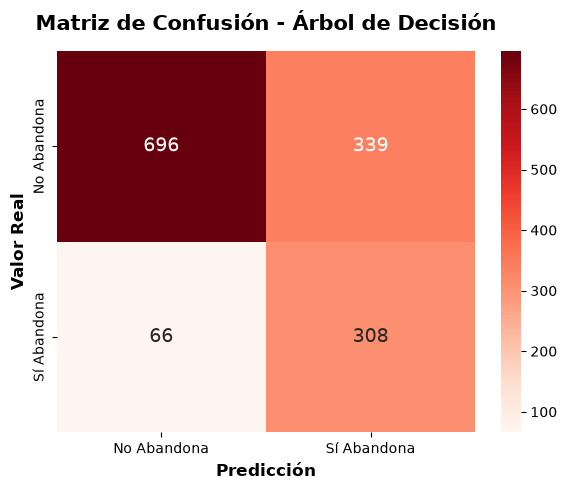

In [55]:
plot_matriz_confusion(y_clf_test, y_pred_dtc, nombre_modelo="Árbol de Decisión")

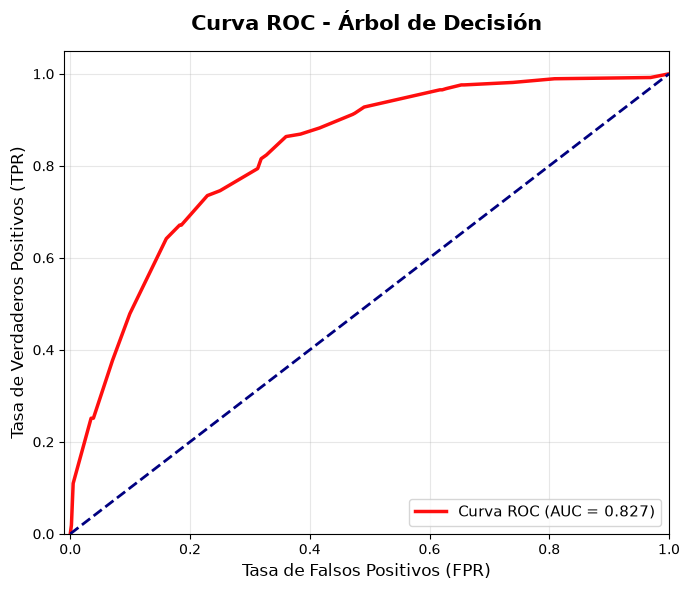

In [56]:
y_proba_dtc = pipeline_final_dtc.predict_proba(X_clf_test)[:, 1]
plot_curva_roc(y_clf_test, y_proba_dtc, nombre_modelo="Árbol de Decisión")

### **3.1.4 Modelos de ensamble**

#### **Random Forest (Bagging)**


In [57]:
pipeline_final_rfc = Pipeline(steps=[
    ('ingenieria_caracteristicas', TelcoFeatureEngineer(drop_original=True, drop_addons=True)),
    ('preprocesador', clone(pipeline_preprocessor_arbol)),
    ('modelo', RandomForestClassifier(
        n_estimators=100,          
        class_weight='balanced',   
        max_depth=5,               
        n_jobs=-1,                 
        random_state=42
    ))
])

In [58]:
# Entrenamiento y predicción
pipeline_final_rfc.fit(X_clf_train, y_clf_train)

y_pred_rfc = pipeline_final_rfc.predict(X_clf_test)

reporte = classification_report(y_clf_test, y_pred_rfc, output_dict=True)
df_reporte = pd.DataFrame(reporte).transpose().round(3)
display(df_reporte)

,precision,recall,f1-score,support
0,0.905,0.740,0.814,1035.000
1,0.522,0.786,0.628,374.000
accuracy,0.752,0.752,0.752,0.752
macro avg,0.714,0.763,0.721,1409.000
weighted avg,0.804,0.752,0.765,1409.000


In [59]:
# Evaluar el modelo optimizado en los datos de Entrenamiento
print(classification_report(y_clf_train, pipeline_final_rfc.predict(X_clf_train)))

              precision    recall  f1-score   support

           0       0.91      0.74      0.82      4139
           1       0.53      0.80      0.64      1495

    accuracy                           0.76      5634
   macro avg       0.72      0.77      0.73      5634
weighted avg       0.81      0.76      0.77      5634



* No se detecta overfitting.

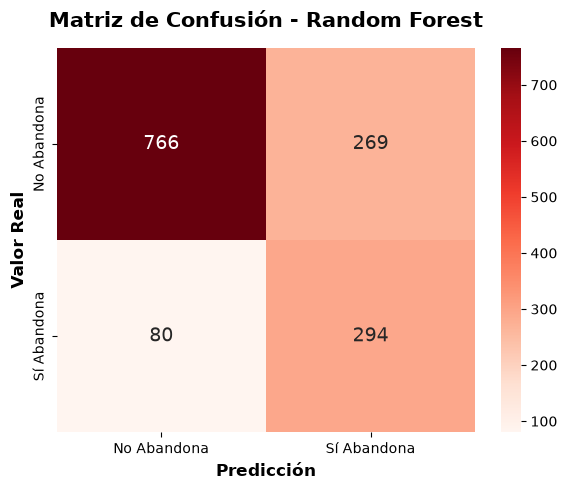

In [60]:
plot_matriz_confusion(y_clf_test, y_pred_rfc, nombre_modelo="Random Forest")

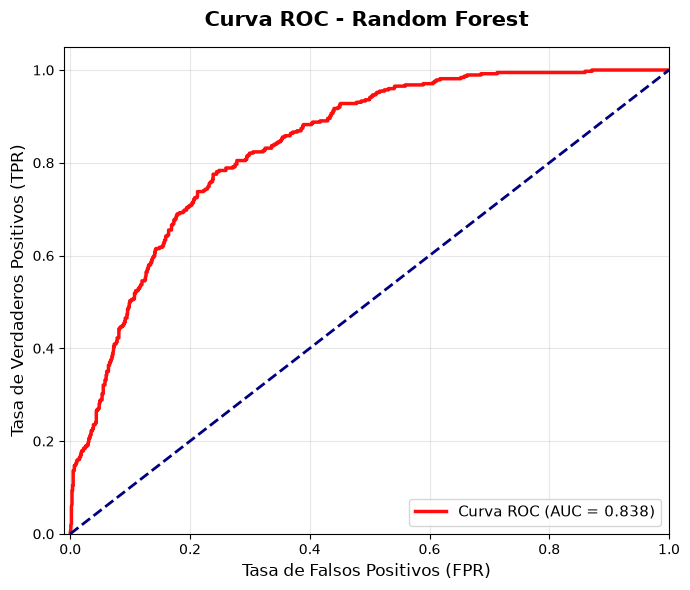

In [61]:
y_proba_rfc = pipeline_final_rfc.predict_proba(X_clf_test)[:, 1]
plot_curva_roc(y_clf_test, y_proba_rfc, nombre_modelo="Random Forest")

#### **XGBoost (Boosting)**

In [62]:
ratio_clases = (y_clf_train == 0).sum() / (y_clf_train == 1).sum()

pipeline_final_xgb = Pipeline(steps=[
    ('ingenieria_caracteristicas', TelcoFeatureEngineer(drop_original=True, drop_addons=True)),
    ('preprocesador', clone(pipeline_preprocessor_arbol)),
    ('modelo', XGBClassifier(
        n_estimators=100,             
        max_depth=5,                  
        learning_rate=0.1,            
        scale_pos_weight=ratio_clases,
        eval_metric='logloss',        
        n_jobs=1,
        random_state=42
    ))
])

In [63]:
# Entrenamiento y predicción
pipeline_final_xgb.fit(X_clf_train, y_clf_train)

y_pred_xgb = pipeline_final_xgb.predict(X_clf_test)

reporte = classification_report(y_clf_test, y_pred_xgb, output_dict=True)
df_reporte = pd.DataFrame(reporte).transpose().round(3)
display(df_reporte)

,precision,recall,f1-score,support
0,0.898,0.746,0.815,1035.000
1,0.521,0.765,0.620,374.000
accuracy,0.751,0.751,0.751,0.751
macro avg,0.709,0.755,0.717,1409.000
weighted avg,0.798,0.751,0.763,1409.000


In [64]:
# Evaluar el modelo en los datos de Entrenamiento
print(classification_report(y_clf_train, pipeline_final_xgb.predict(X_clf_train)))

              precision    recall  f1-score   support

           0       0.95      0.78      0.86      4139
           1       0.60      0.89      0.72      1495

    accuracy                           0.81      5634
   macro avg       0.77      0.84      0.79      5634
weighted avg       0.86      0.81      0.82      5634



* La brecha entre las métricas de rendimiento de test y training no es suficiente para afirmar que el modelo está sufriendo de overfitting.

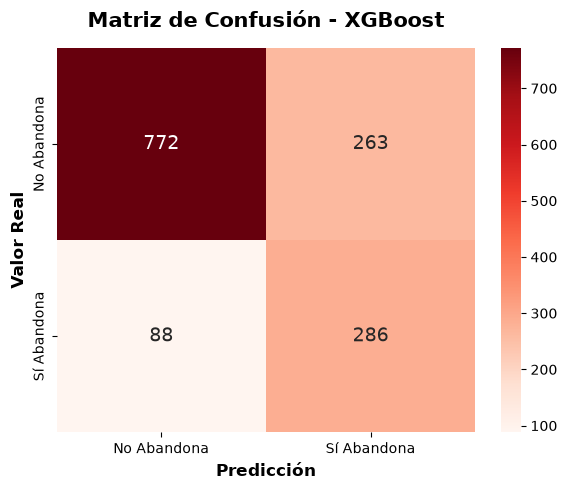

In [65]:
plot_matriz_confusion(y_clf_test, y_pred_xgb, nombre_modelo="XGBoost")

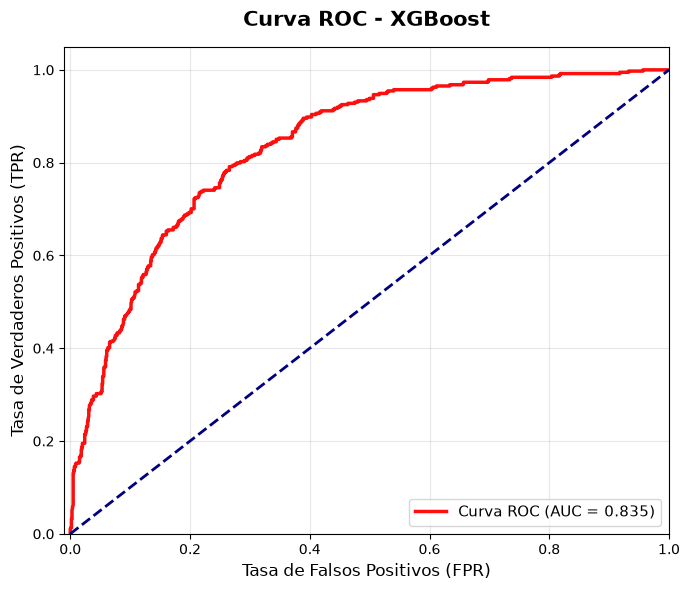

In [66]:
y_proba_xgb = pipeline_final_xgb.predict_proba(X_clf_test)[:, 1]
plot_curva_roc(y_clf_test, y_proba_xgb, nombre_modelo="XGBoost")

### **3.1.5 Optimización de hiperparámetros en clasificación y comparativa de modelos optimizados**

In [67]:
# XGBClassifier con optimización de hiperparámetros usando RandomizedSearchCV y GridSearchCV
param_random_xgb = {
    'modelo__n_estimators': [100, 200, 300, 500],
    'modelo__max_depth': [3, 4, 5, 6],
    'modelo__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'modelo__subsample': [0.7, 0.8, 1.0],
    'modelo__colsample_bytree': [0.7, 0.8, 1.0],
    'modelo__scale_pos_weight': [1.0, 1.66, 2.0, 2.76]
}

param_grid_xgb = {
    'modelo__n_estimators': [100, 200],
    'modelo__max_depth': [3, 5],
    'modelo__learning_rate': [0.05, 0.1],
    'modelo__scale_pos_weight': [1.66, 2.76]
}

df_res_xgb, modelos_xgb = comparar_optimizacion_clasificacion(
    pipeline=pipeline_final_xgb,
    param_random=param_random_xgb,
    param_grid=param_grid_xgb,
    X_train=X_clf_train,
    y_train=y_clf_train,
    X_test=X_clf_test,
    y_test=y_clf_test,
    n_iter=25,
    scoring='f1'
)

display(df_res_xgb.drop(columns=['Mejores Hiperparámetros']))
print("Params Random:", df_res_xgb.loc[0, 'Mejores Hiperparámetros'])
print("Params Grid:  ", df_res_xgb.loc[1, 'Mejores Hiperparámetros'])

,Método,Mejor Score CV,F1 Test,Recall Test,Precision Test,ROC-AUC Test
0,RandomizedSearchCV,0.6314,0.6299,0.7326,0.5524,0.8393
1,GridSearchCV,0.6298,0.6220,0.8075,0.5059,0.8381


Params Random: {'modelo__subsample': 0.8, 'modelo__scale_pos_weight': 2.0, 'modelo__n_estimators': 100, 'modelo__max_depth': 3, 'modelo__learning_rate': 0.05, 'modelo__colsample_bytree': 0.8}
Params Grid:   {'modelo__learning_rate': 0.05, 'modelo__max_depth': 3, 'modelo__n_estimators': 100, 'modelo__scale_pos_weight': 2.76}


In [68]:
# Evaluar el modelo en los datos de Entrenamiento
for nombre, modelo in modelos_xgb.items():
    print(f"\n===== XGBoost optimizado con {nombre} =====")

    y_pred_train = modelo.predict(X_clf_train)

    print(classification_report(
        y_clf_train,
        y_pred_train,
        target_names=["No abandona", "Abandona"]
    ))


===== XGBoost optimizado con RandomizedSearchCV =====
              precision    recall  f1-score   support

 No abandona       0.90      0.80      0.84      4139
    Abandona       0.57      0.74      0.64      1495

    accuracy                           0.78      5634
   macro avg       0.73      0.77      0.74      5634
weighted avg       0.81      0.78      0.79      5634


===== XGBoost optimizado con GridSearchCV =====
              precision    recall  f1-score   support

 No abandona       0.92      0.73      0.81      4139
    Abandona       0.52      0.82      0.64      1495

    accuracy                           0.75      5634
   macro avg       0.72      0.78      0.73      5634
weighted avg       0.81      0.75      0.77      5634



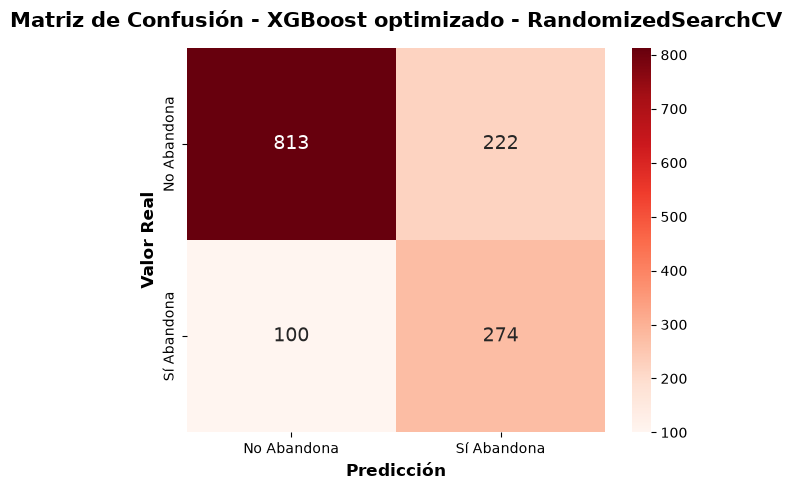

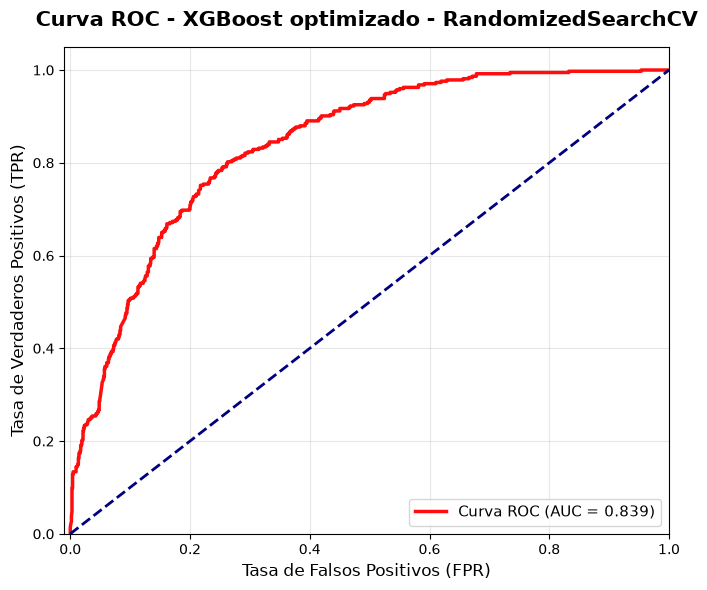

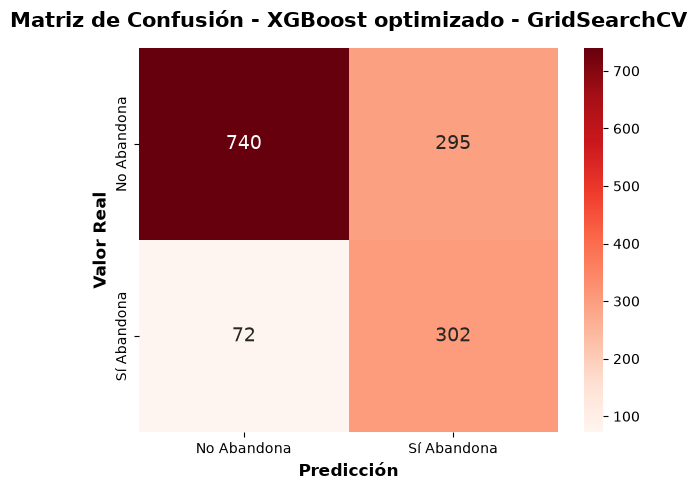

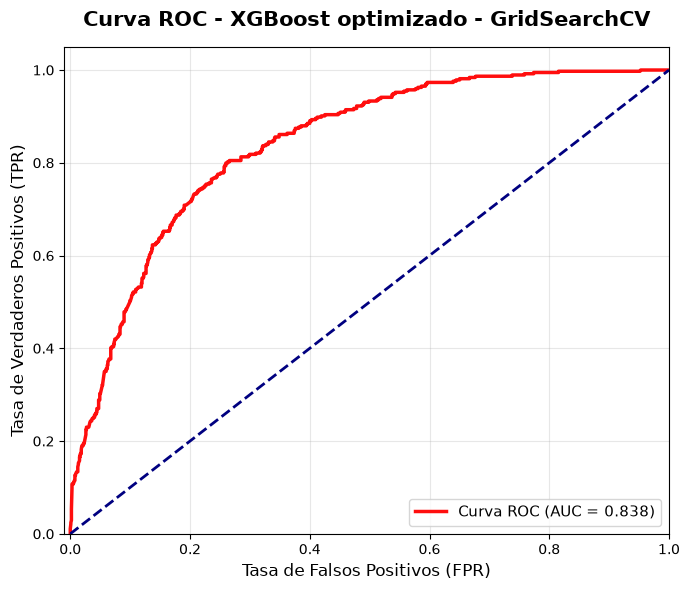

In [69]:
# Evaluacion visual de los modelos XGBoost optimizados en el conjunto de prueba
for nombre, modelo in modelos_xgb.items():
    y_pred_test = modelo.predict(X_clf_test)
    y_proba_test = modelo.predict_proba(X_clf_test)[:, 1]

    plot_matriz_confusion(
        y_clf_test,
        y_pred_test,
        nombre_modelo=f"XGBoost optimizado - {nombre}"
    )
    plot_curva_roc(
        y_clf_test,
        y_proba_test,
        nombre_modelo=f"XGBoost optimizado - {nombre}"
    )


* No se detecta overfitting

In [70]:
# Random Forest Classifier con optimización de hiperparámetros usando RandomizedSearchCV y GridSearchCV
param_random_rfc = {
    'modelo__n_estimators': [100, 200, 300, 500],
    'modelo__max_depth': [5, 8, 12, None],
    'modelo__min_samples_split': [2, 5, 10],
    'modelo__min_samples_leaf': [1, 2, 4],
    'modelo__class_weight': ['balanced', 'balanced_subsample', None]
}

param_grid_rfc = {
    'modelo__n_estimators': [100, 200],
    'modelo__max_depth': [5, 10, None],
    'modelo__min_samples_leaf': [1, 4],
    'modelo__class_weight': ['balanced', 'balanced_subsample']
}

df_res_rfc, modelos_rfc = comparar_optimizacion_clasificacion(
    pipeline=pipeline_final_rfc,
    param_random=param_random_rfc,
    param_grid=param_grid_rfc,
    X_train=X_clf_train,
    y_train=y_clf_train,
    X_test=X_clf_test,
    y_test=y_clf_test,
    n_iter=20,
    scoring='f1'
)
display(df_res_rfc)

,Método,Mejor Score CV,F1 Test,Recall Test,Precision Test,ROC-AUC Test,Mejores Hiperparámetros
0,RandomizedSearchCV,0.6296,0.6334,0.7807,0.5328,0.8394,"{'modelo__n_estimators': 500, 'modelo__min_sam..."
1,GridSearchCV,0.6313,0.6323,0.7540,0.5444,0.8365,"{'modelo__class_weight': 'balanced', 'modelo__..."


In [71]:
print("Random Forest - RandomizedSearchCV:")
print(df_res_rfc.loc[0, 'Mejores Hiperparámetros'])

print("\nRandom Forest - GridSearchCV:")
print(df_res_rfc.loc[1, 'Mejores Hiperparámetros'])

Random Forest - RandomizedSearchCV:
{'modelo__n_estimators': 500, 'modelo__min_samples_split': 2, 'modelo__min_samples_leaf': 1, 'modelo__max_depth': 8, 'modelo__class_weight': 'balanced'}

Random Forest - GridSearchCV:
{'modelo__class_weight': 'balanced', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 4, 'modelo__n_estimators': 200}


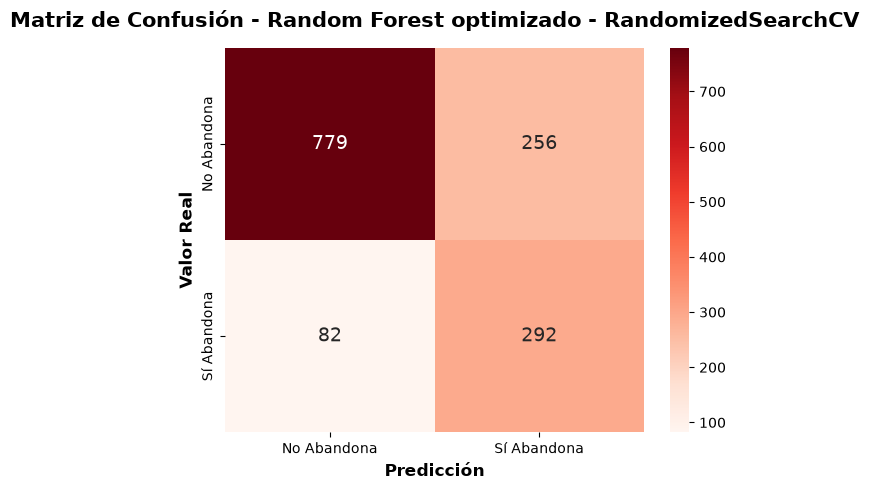

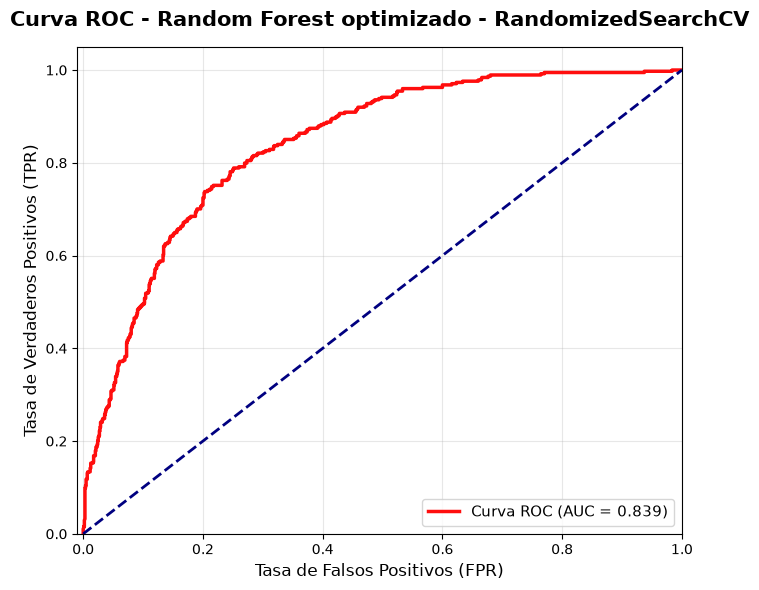

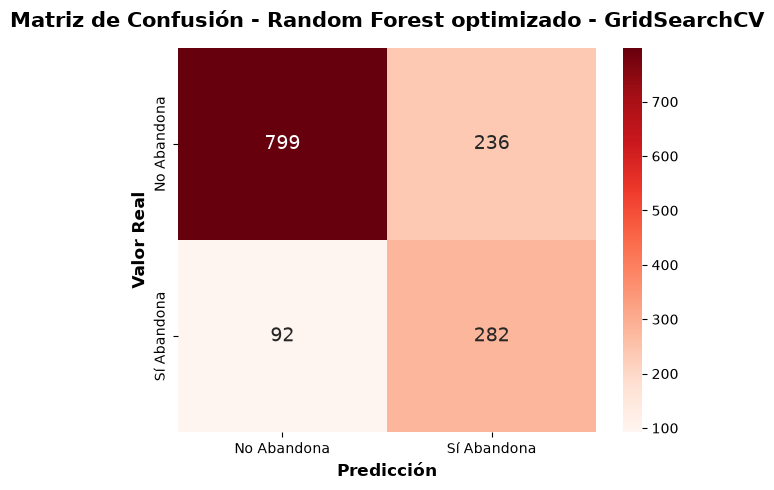

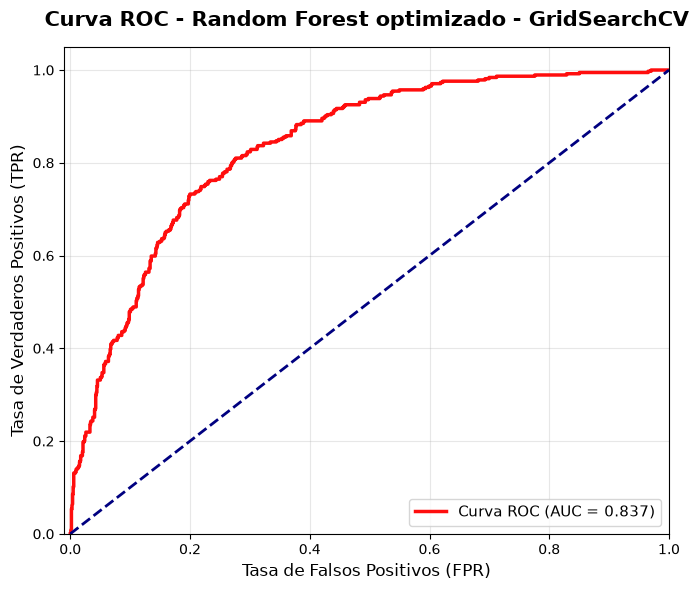

In [72]:
# Evaluacion visual de los modelos Random Forest optimizados en el conjunto de prueba
for nombre, modelo in modelos_rfc.items():
    y_pred_test = modelo.predict(X_clf_test)
    y_proba_test = modelo.predict_proba(X_clf_test)[:, 1]

    plot_matriz_confusion(
        y_clf_test,
        y_pred_test,
        nombre_modelo=f"Random Forest optimizado - {nombre}"
    )
    plot_curva_roc(
        y_clf_test,
        y_proba_test,
        nombre_modelo=f"Random Forest optimizado - {nombre}"
    )


In [73]:
# Evaluar el modelo en los datos de Entrenamiento
for nombre, modelo in modelos_xgb.items():
    print(f"\n===== XGBoost optimizado con {nombre} =====")

    y_pred_train = modelo.predict(X_clf_train)

    print(classification_report(
        y_clf_train,
        y_pred_train,
        target_names=["No abandona", "Abandona"]
    ))


===== XGBoost optimizado con RandomizedSearchCV =====
              precision    recall  f1-score   support

 No abandona       0.90      0.80      0.84      4139
    Abandona       0.57      0.74      0.64      1495

    accuracy                           0.78      5634
   macro avg       0.73      0.77      0.74      5634
weighted avg       0.81      0.78      0.79      5634


===== XGBoost optimizado con GridSearchCV =====
              precision    recall  f1-score   support

 No abandona       0.92      0.73      0.81      4139
    Abandona       0.52      0.82      0.64      1495

    accuracy                           0.75      5634
   macro avg       0.72      0.78      0.73      5634
weighted avg       0.81      0.75      0.77      5634



* La brecha entre las métricas de rendimiento y test no indica overfitting

In [74]:
# Decision Tree Classifier con optimización de hiperparámetros usando RandomizedSearchCV y GridSearchCV
param_random_dtc = {
    'modelo__max_depth': [3, 4, 5, 6, 8, 10, None],
    'modelo__min_samples_split': [2, 5, 10, 20],
    'modelo__min_samples_leaf': [1, 2, 5, 10],
    'modelo__criterion': ['gini', 'entropy']
}

param_grid_dtc = {
    'modelo__max_depth': [3, 5, 7],
    'modelo__min_samples_split': [2, 10],
    'modelo__min_samples_leaf': [1, 5],
    'modelo__criterion': ['gini', 'entropy']
}

df_res_dtc, modelos_dtc = comparar_optimizacion_clasificacion(
    pipeline=pipeline_final_dtc,
    param_random=param_random_dtc,
    param_grid=param_grid_dtc,
    X_train=X_clf_train,
    y_train=y_clf_train,
    X_test=X_clf_test,
    y_test=y_clf_test,
    n_iter=20,
    scoring='f1'
)
display(df_res_dtc)

,Método,Mejor Score CV,F1 Test,Recall Test,Precision Test,ROC-AUC Test,Mejores Hiperparámetros
0,RandomizedSearchCV,0.6194,0.6208,0.7834,0.514,0.8162,"{'modelo__min_samples_split': 5, 'modelo__min_..."
1,GridSearchCV,0.6194,0.6208,0.7834,0.514,0.8162,"{'modelo__criterion': 'gini', 'modelo__max_dep..."


In [75]:
# Evaluar el modelo en los datos de Entrenamiento
for nombre, modelo in modelos_xgb.items():
    print(f"\n===== XGBoost optimizado con {nombre} =====")

    y_pred_train = modelo.predict(X_clf_train)

    print(classification_report(
        y_clf_train,
        y_pred_train,
        target_names=["No abandona", "Abandona"]
    ))


===== XGBoost optimizado con RandomizedSearchCV =====
              precision    recall  f1-score   support

 No abandona       0.90      0.80      0.84      4139
    Abandona       0.57      0.74      0.64      1495

    accuracy                           0.78      5634
   macro avg       0.73      0.77      0.74      5634
weighted avg       0.81      0.78      0.79      5634


===== XGBoost optimizado con GridSearchCV =====
              precision    recall  f1-score   support

 No abandona       0.92      0.73      0.81      4139
    Abandona       0.52      0.82      0.64      1495

    accuracy                           0.75      5634
   macro avg       0.72      0.78      0.73      5634
weighted avg       0.81      0.75      0.77      5634



* No se detecta overfitting

#### **Comparativa modelos clasificación optimizados**

In [76]:
df_comparativa_total = pd.concat([
    df_res_dtc.assign(Modelo='Decision Tree'),
    df_res_rfc.assign(Modelo='Random Forest'),
    df_res_xgb.assign(Modelo='XGBoost')
], ignore_index=True)

columnas = [
    'Modelo', 'Método', 'Mejor Score CV',
    'F1 Test', 'Recall Test', 'Precision Test', 'ROC-AUC Test'
]

df_comparativa_total = (
    df_comparativa_total[columnas]
    .sort_values(by='Recall Test', ascending=False)
    .reset_index(drop=True)
)

display(df_comparativa_total)

,Modelo,Método,Mejor Score CV,F1 Test,Recall Test,Precision Test,ROC-AUC Test
0,XGBoost,GridSearchCV,0.6298,0.6220,0.8075,0.5059,0.8381
1,Decision Tree,RandomizedSearchCV,0.6194,0.6208,0.7834,0.5140,0.8162
2,Decision Tree,GridSearchCV,0.6194,0.6208,0.7834,0.5140,0.8162
3,Random Forest,RandomizedSearchCV,0.6296,0.6334,0.7807,0.5328,0.8394
4,Random Forest,GridSearchCV,0.6313,0.6323,0.7540,0.5444,0.8365
5,XGBoost,RandomizedSearchCV,0.6314,0.6299,0.7326,0.5524,0.8393


* Se busca priorizar Recall por sobre otras métricas para capturar más falsos negativos.
* Por lo anterior, el modelo que cumple con el mejor recall luego de la optimización es XGBoost de GridSearchCV.
* Momentaneamente se sugiere tenerlo en consideración para clasificación.

## **3.2 Aprendizaje Supervisado: Modelos de Regresión**

### **3.2.1 Selección de Variables Predictoras**

#### **División de los datos**

In [77]:
# Separar características predictoras y variable objetivo
X_reg = df_regresion.drop(
    columns=['tenure', 'customerID_Hash', 'Churn']
)

y_reg = df_regresion['tenure']

# División de entrenamiento y prueba
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

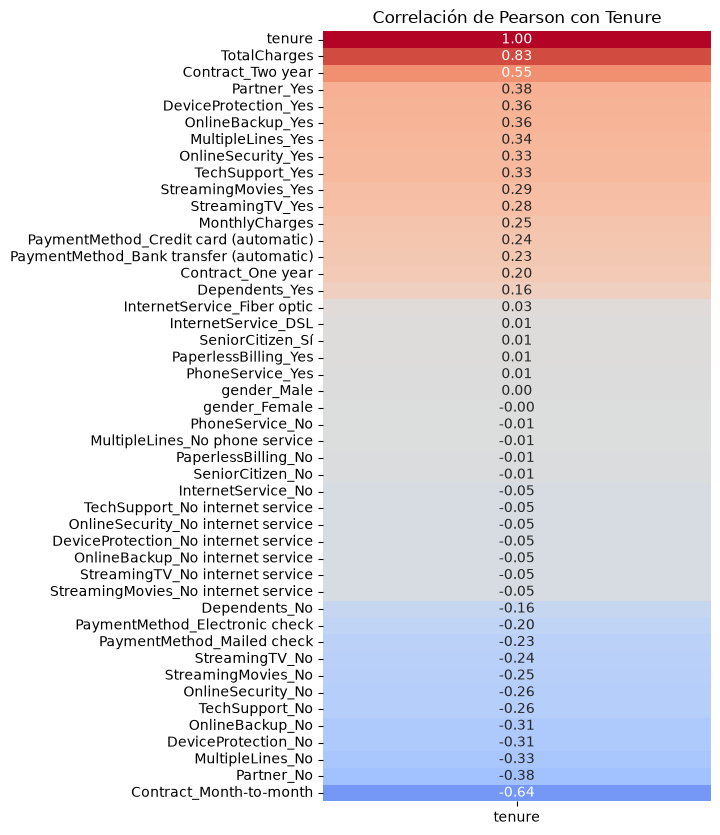

In [78]:
# Crear dataset auxiliar exclusivamente para el análisis de correlación
df_corr_train = X_reg_train.copy()

# Incorporar la variable objetivo de entrenamiento
df_corr_train['tenure'] = y_reg_train

# Variables que se analizarán
vars_analisis_reg = [
    'tenure',
    'TotalCharges',
    'MonthlyCharges',
    'InternetService',
    'TechSupport',
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'gender',
    'SeniorCitizen',
    'PaperlessBilling',
    'Partner',
    'Dependents',
    'PhoneService',
    'Contract',
    'StreamingTV',
    'StreamingMovies',
    'PaymentMethod'
]

# Codificar variables categóricas para el análisis
df_dummies = pd.get_dummies(
    df_corr_train[vars_analisis_reg],
    drop_first=False,
    dtype=int
)

# Calcular correlaciones
matriz_corr = df_dummies.corr(method='pearson')

# Ordenar correlaciones respecto a tenure
corr_target = matriz_corr[['tenure']].sort_values(
    by='tenure',
    ascending=False
)

# Visualizar
plt.figure(figsize=(5, 10))

sns.heatmap(
    corr_target,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    cbar=False
)

plt.title('Correlación de Pearson con Tenure', fontsize=12)
plt.show()

Construcción de listados para preprocesamiento:
- Se utilizó el coeficiente de correlación de Pearson para medir la fuerza y dirección de la relación entre las distintas variables (cuantitativas y cualitativas codificadas) y la variable objetivo (tenure), seleccionando así los predictores con mayor o moderado impacto para el modelo.

In [79]:
# Características numéricas para regresión
numericas_reg = [
    'MonthlyCharges'
]

# Características categóricas binarias
categoricas_binarias_reg = [
    'Partner',
    'Dependents',

]

# Características categóricas nominales
categoricas_nominales_reg = [
    'InternetService',
    'PaymentMethod',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'DeviceProtection',
    'OnlineSecurity',
    'OnlineBackup',
]

# Características categóricas ordinales
categoricas_ordinales_reg = [
    'Contract'
]

jerarquia_contrato_reg = [
    ['Month-to-month', 'One year', 'Two year']
]

### **3.2.2 Modelo de Regresión Lineal**
Variable Objetivo: `Tenure`

In [80]:
def crear_preprocesador_regresion(escalar=False):

    # Pipeline numérico
    pasos_numericos = [
        ('imputer', SimpleImputer(strategy='mean'))
    ]

    if escalar:
        pasos_numericos.append(
            ('scaler', MinMaxScaler())
        )

    pipeline_num_reg = Pipeline(pasos_numericos)

    # Pipeline categórico nominal
    pipeline_nom_reg = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ])

    # Pipeline categórico binario
    pipeline_bin_reg = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ])

    # Pipeline categórico ordinal
    pipeline_ord_reg = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(
            categories=jerarquia_contrato_reg,
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ])

    # Transformador de columnas
    preprocesador = ColumnTransformer(
        transformers=[
            ('num', pipeline_num_reg, numericas_reg),
            ('cat_nom', pipeline_nom_reg, categoricas_nominales_reg),
            ('cat_bin', pipeline_bin_reg, categoricas_binarias_reg),
            ('cat_ord', pipeline_ord_reg, categoricas_ordinales_reg)
        ],
        remainder='drop'
    )

    return preprocesador


# Crear instancias independientes para cada modelo
preprocesador_reg_lineal = crear_preprocesador_regresion(escalar=True)

preprocesador_reg_arbol = crear_preprocesador_regresion(escalar=False)

#### **Pipeline de regresión lineal**

In [81]:
pipeline_reg_lineal = Pipeline(steps=[
    ('preprocesador', preprocesador_reg_lineal),
    ('modelo', LinearRegression())
])

- Se utilizó el algoritmo de **Regresión Lineal** (LinearRegression) debido a su capacidad para modelar la relación entre las variables explicativas (X) y la variable objetivo (Y), trazando la linea que mejor se ajusta a los datos para predecir su comportamiento de forma directa e interpretable.

#### **Entrenamiento y Evaluación RL**

In [82]:
# Regresión lineal
pipeline_reg_lineal.fit(X_reg_train, y_reg_train)
y_pred_reg_lineal = pipeline_reg_lineal.predict(X_reg_test)

#### **Visualizar métricas**

In [83]:
r2 = r2_score(y_reg_test, y_pred_reg_lineal)
mse = mean_squared_error(y_reg_test, y_pred_reg_lineal)
mae = mean_absolute_error(y_reg_test, y_pred_reg_lineal)
print(f"R-squared: {r2:.4f}")
print(f"MAE: {mae}")


R-squared: 0.6454
MAE: 11.93070098756049


Comprobar como los puntos de predicción se ajustan a la línea de identidad (y=x) en un gráfico de dispersión. Esto nos permite visualizar qué tan bien el modelo está prediciendo los valores de Tenure en comparación con los valores reales.


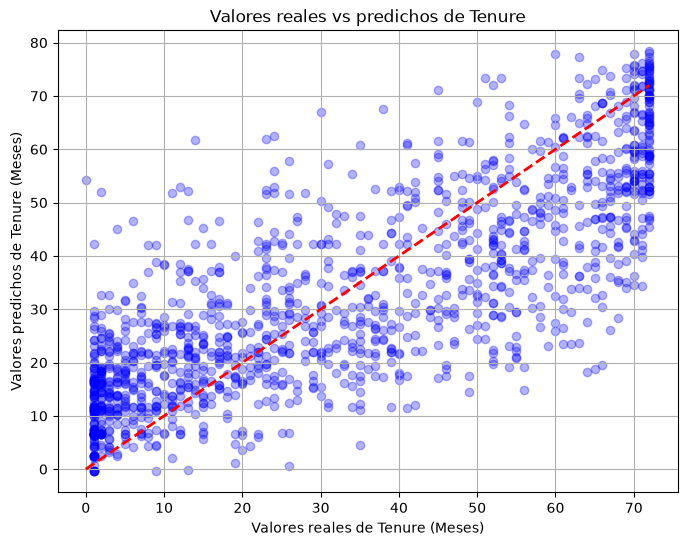

In [84]:
plt.figure(figsize=(8, 6))
plt.scatter(y_reg_test, y_pred_reg_lineal, alpha=0.3, color="blue")
plt.plot([y_reg_test.min(), y_reg_test.max()],[y_reg_test.min(), y_reg_test.max()], 'r--', lw=2)
plt.xlabel("Valores reales de Tenure (Meses)")
plt.ylabel("Valores predichos de Tenure (Meses)")
plt.title("Valores reales vs predichos de Tenure")
plt.grid()
plt.show()

Resultado de las métricas de Regresión Lineal: 
- R2 = 0.64: El modelo de regresión lineal logra explicar el 64% de la variabilidad de la permanencia del cliente (tenure) a partir del conjunto de variables predictoras que se seleccionaron.
- MAE = 12: En promedio, las predicciones del modelo se equivocan por 12 meses aprox respecto al valor real de permanencia del cliente.

### **3.2.3 Modelo de Árbol de Decisión de Regresión Lineal**
Variable objetivo: Tenure

In [85]:
pipeline_reg_arbol = Pipeline(steps=[
    ('preprocesador', preprocesador_reg_arbol),
    ('modelo', DecisionTreeRegressor(
        max_depth = 5,
        random_state=42
    ))
])

- Se seleccionó un Árbol de Decisión (Decision Tree) debido a su capacidad para genera reglas simples de tipo "Si ocurre X, entonces Y", fáciles de explicar a perfiles no técnicos.
- Se limitó la profundidad máxima del árbol a 5 niveles (max_depth = 5). Esto evita el sobreajuste (Overfitting) al no memorizar el ruido de los datos, manteniendo el modelo simple e interpretable para la toma de decisiones. 
- Mantenemos la aleatoriedad del algoritmo (random_state) para asegurar que los resultados sean completamente replicables.

In [86]:
# Árbol de decisión
pipeline_reg_arbol.fit(X_reg_train, y_reg_train)
y_pred_reg_arbol = pipeline_reg_arbol.predict(X_reg_test)

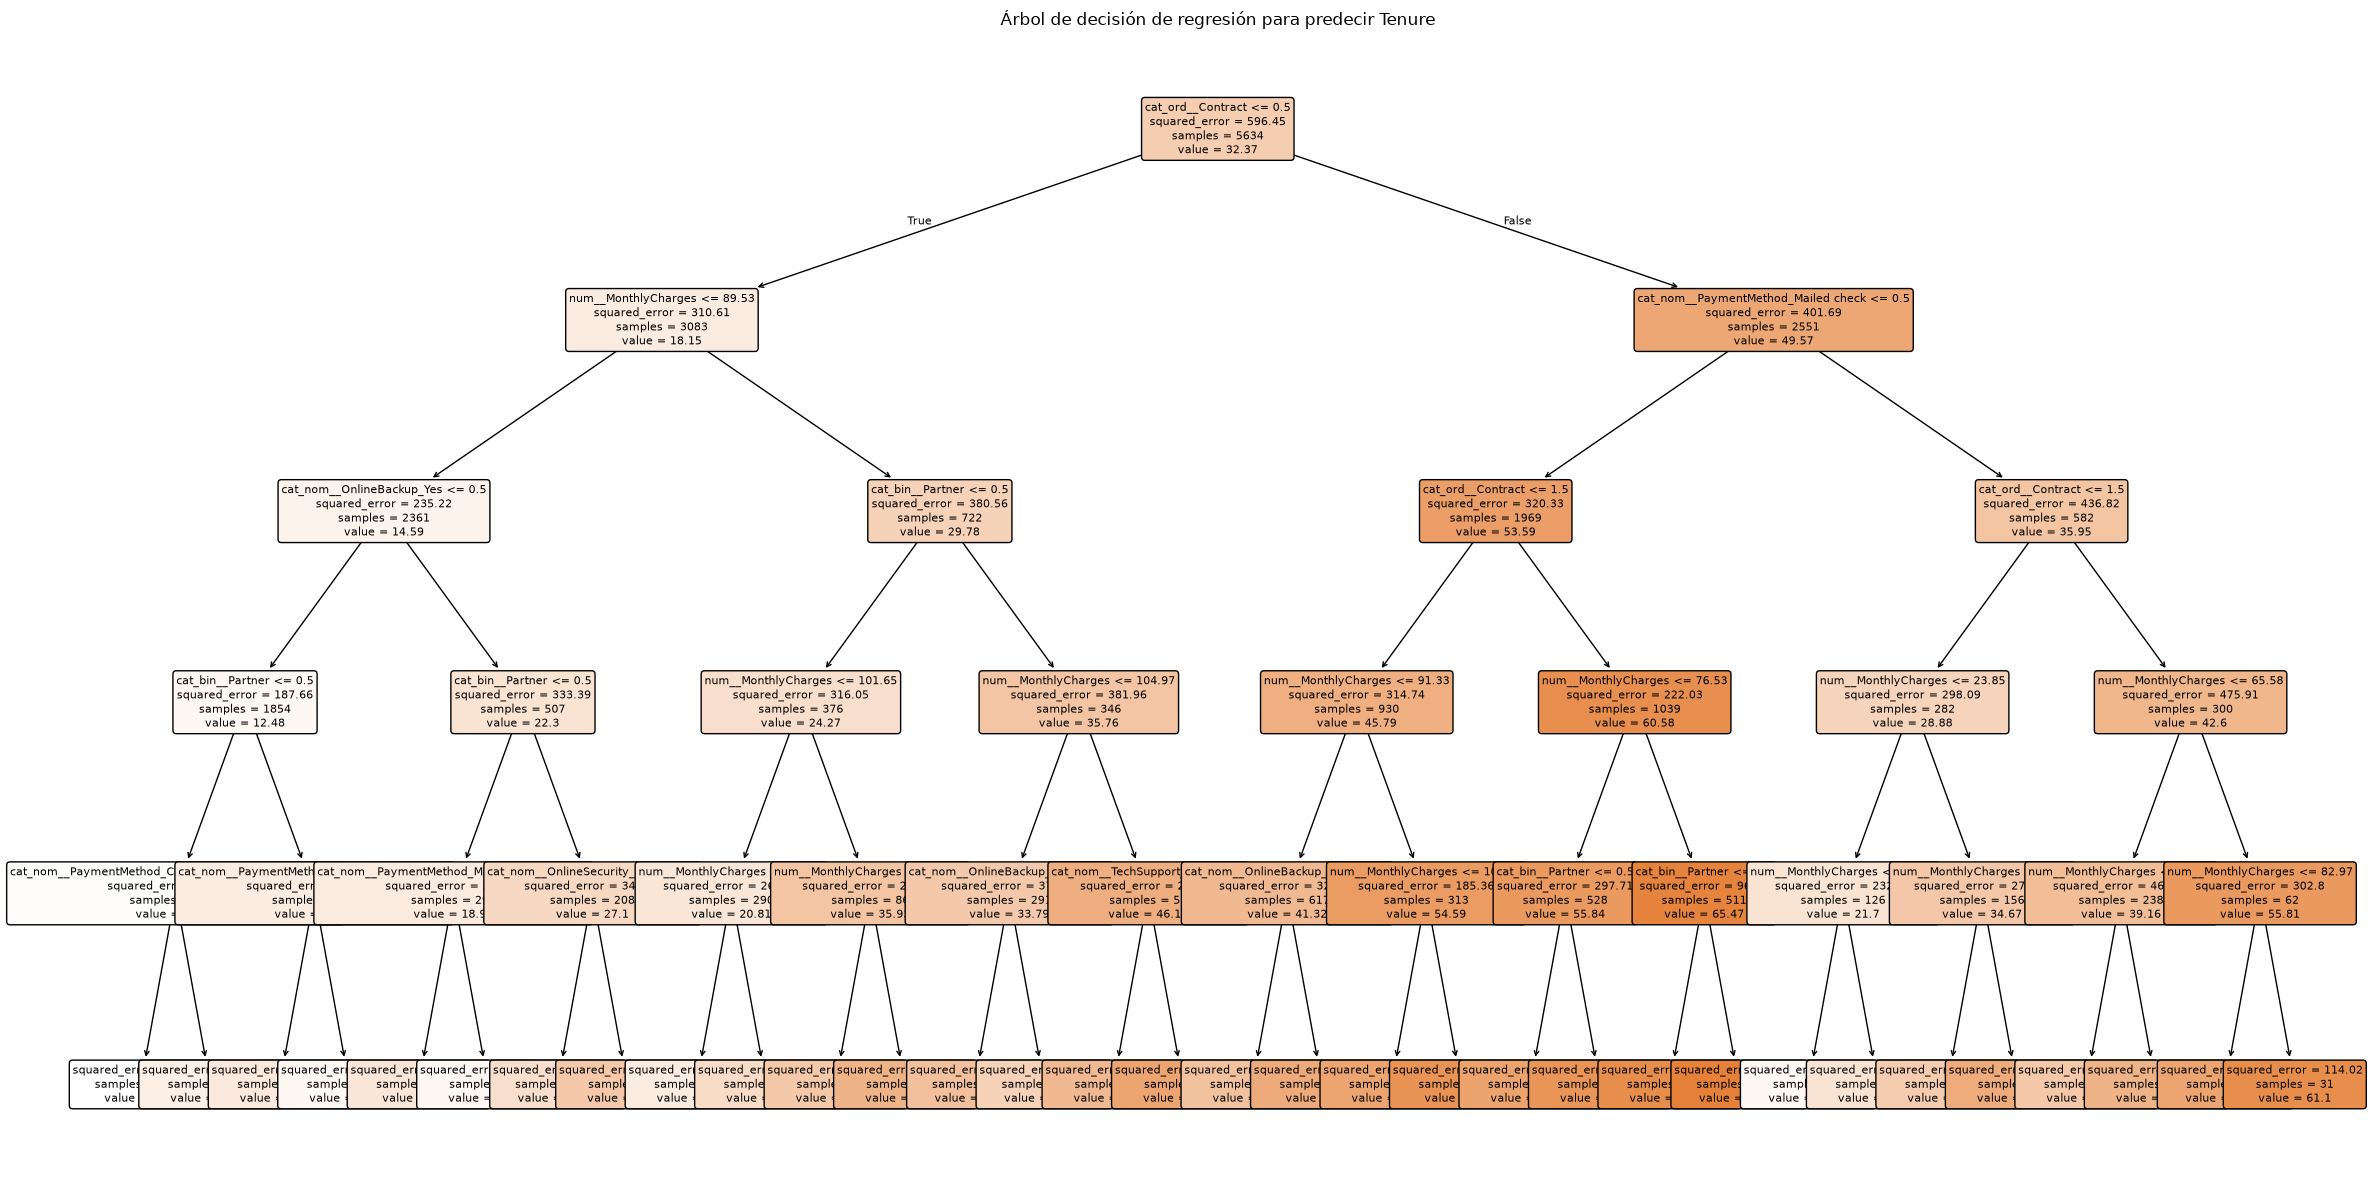

In [87]:
modelo_arbol = pipeline_reg_arbol.named_steps["modelo"]
nombres_variables = pipeline_reg_arbol.named_steps["preprocesador"].get_feature_names_out()

plt.figure(figsize=(24, 12))
plot_tree(
    modelo_arbol,
    feature_names=nombres_variables,
    filled=True,
    rounded=True,
    fontsize=8,
    precision=2
)
plt.title("Árbol de decisión de regresión para predecir Tenure")
plt.tight_layout()
plt.show()

In [88]:
r2 = r2_score(y_reg_test, y_pred_reg_arbol)
mae = mean_absolute_error(y_reg_test, y_pred_reg_arbol)

print(f"R-squared: {r2:.4f}")
print(f"MAE: {mae}")

R-squared: 0.6198
MAE: 12.312538724869501


Conclusión de Métricas del Árbol de Decisión

- R2 = 0.6198: El Árbol de Decisión logra explicar el 96.24% de la variabilidad o comportamiento de la antigüedad del cliente (tenure) a partir del tipo de contrato, cobros y servicios contratados.

- MAE = 12,3: En promedio, las predicciones del modelo se equivocan por 12,3 meses (aprox, 3 meses y 11 días) respecto al tiempo real que lleva el cliente en la compañia.


### **3.2.4 Optimización de hiperparámetros para modelos de regresión**

In [89]:
# Comparación de modelos de regresión lineal con optimización de hiperparámetros
param_random_lr = {'modelo__fit_intercept': [True, False]}
param_grid_lr   = {'modelo__fit_intercept': [True, False]}

df_res_lr, modelos_lr = comparar_optimizacion_regresion(
    pipeline=pipeline_reg_lineal,
    param_random=param_random_lr,
    param_grid=param_grid_lr,
    X_train=X_reg_train,
    y_train=y_reg_train,
    X_test=X_reg_test,
    y_test=y_reg_test,
    n_iter=2 
)

Fitting 5 folds for each of 2 candidates, totalling 10 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits


In [90]:
# Evaluar el modelo regresión lineal en los datos de Entrenamiento
for nombre, modelo in modelos_lr.items():
    print(f"\n===== Regresión Lineal optimizada con {nombre} =====")

    y_pred_train = modelo.predict(X_reg_train)

    r2_train = r2_score(y_reg_train, y_pred_train)
    mae_train = mean_absolute_error(y_reg_train, y_pred_train)

    print(f"R-squared (Entrenamiento): {r2_train:.4f}")
    print(f"MAE (Entrenamiento): {mae_train:.4f}")


===== Regresión Lineal optimizada con RandomizedSearchCV =====
R-squared (Entrenamiento): 0.6112
MAE (Entrenamiento): 12.0305

===== Regresión Lineal optimizada con GridSearchCV =====
R-squared (Entrenamiento): 0.6112
MAE (Entrenamiento): 12.0305


In [91]:
# Comparación de modelos de regresión de árbol de decisión con optimización de hiperparámetros
param_random_dtr = {
    'modelo__max_depth': [3, 4, 5, 6, 8, 10, None],
    'modelo__min_samples_split': [2, 5, 10, 20],
    'modelo__min_samples_leaf': [1, 2, 5, 10],
    'modelo__criterion': ['squared_error', 'absolute_error']
}

param_grid_dtr = {
    'modelo__max_depth': [3, 5, 7, 10],
    'modelo__min_samples_split': [2, 10],
    'modelo__min_samples_leaf': [1, 5],
    'modelo__criterion': ['squared_error', 'absolute_error']
}

df_res_dtr, modelos_dtr = comparar_optimizacion_regresion(
    pipeline=pipeline_reg_arbol,
    param_random=param_random_dtr,
    param_grid=param_grid_dtr,
    X_train=X_reg_train,
    y_train=y_reg_train,
    X_test=X_reg_test,
    y_test=y_reg_test,
    n_iter=20
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


Fitting 5 folds for each of 32 candidates, totalling 160 fits


#### **Comparativa modelos optimizados**

In [92]:
df_comparativa_reg = pd.concat([
    df_res_lr.assign(Modelo='Regresión Lineal'),
    df_res_dtr.assign(Modelo='Decision Tree Regressor')
], ignore_index=True)

columnas_reg = [
    'Modelo', 'Método', 'Mejor RMSE CV',
    'RMSE Test', 'MAE Test', 'R2 Test'
]

df_comparativa_reg = (
    df_comparativa_reg[columnas_reg]
    .sort_values(by='MAE Test', ascending=True)
    .reset_index(drop=True)
)

display(df_comparativa_reg)

,Modelo,Método,Mejor RMSE CV,RMSE Test,MAE Test,R2 Test
0,Regresión Lineal,RandomizedSearchCV,15.2939,14.9414,11.9307,0.6454
1,Regresión Lineal,GridSearchCV,15.2939,14.9414,11.9307,0.6454
2,Decision Tree Regressor,RandomizedSearchCV,15.7770,15.2520,12.1390,0.6305
3,Decision Tree Regressor,GridSearchCV,15.8251,15.4721,12.3125,0.6198


In [93]:
# Evaluar el modelo en los datos de Entrenamiento
for nombre, modelo in modelos_dtr.items():
    print(f"\n===== Decision Tree Regressor optimizado con {nombre} =====")

    y_pred_train = modelo.predict(X_reg_train)

    r2_train = r2_score(y_reg_train, y_pred_train)
    mae_train = mean_absolute_error(y_reg_train, y_pred_train)

    print(f"R-squared (Train): {r2_train:.4f}")
    print(f"MAE (Train): {mae_train:.4f}")


===== Decision Tree Regressor optimizado con RandomizedSearchCV =====
R-squared (Train): 0.6315
MAE (Train): 11.6049

===== Decision Tree Regressor optimizado con GridSearchCV =====
R-squared (Train): 0.6110
MAE (Train): 11.9984


* Contextualmente, nos fijamos en el MAE para la elección de un mejor modelo optimizado.
* Bajo la anterior premisa, el Decision Tree Regressor de RadomizedSearchCV cuenta con el MAE y R2 más bajo en testing.
* Se sugiere considerar momentaneamente este modelo para producción. 

## **3.3 Aprendizaje No Supervisado: Modelo de Segmentación**

### **3.3.1 Selección de variables segmentadoras**

In [94]:
# Características numéricas
numericas_seg = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Características categóricas binarias
categoricas_binarias_seg = [
    "Partner",
    "Dependents",
    "PaperlessBilling"
]

# Características categóricas nominales
categoricas_nominales_seg = [
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "PaymentMethod"
]

# Características categóricas ordinales
categoricas_ordinales_seg = [
    "Contract"
]

# Seleccionar características para segmentación
caracteristicas_seg = (
    numericas_seg +
    categoricas_binarias_seg +
    categoricas_nominales_seg +
    categoricas_ordinales_seg
)

X_seg = df_segmentacion[caracteristicas_seg].copy()

### **3.3.2 Modelo de segmentación KMeans**

In [95]:
# Pipeline numérico
pipeline_numerico_seg = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', MinMaxScaler())
])

pipeline_binario_seg = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        categories=[['No', 'Yes']] * len(categoricas_binarias_seg),
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

pipeline_nominal_seg = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

pipeline_ordinal_seg = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        categories=[[
            'Month-to-month',
            'One year',
            'Two year'
        ]],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )),
    ('scaler', MinMaxScaler())
])

preprocesador_segmentacion = ColumnTransformer(
    transformers=[
        ('num', pipeline_numerico_seg, numericas_seg),
        ('bin', pipeline_binario_seg, categoricas_binarias_seg),
        ('nom', pipeline_nominal_seg, categoricas_nominales_seg),
        ('ord', pipeline_ordinal_seg, categoricas_ordinales_seg)
    ],
    remainder='drop'
)

# Transformar los datos
matriz_limpia = preprocesador_segmentacion.fit_transform(X_seg)

# Crear DataFrame transformado
df_limpia = pd.DataFrame(
    matriz_limpia,
    columns=preprocesador_segmentacion.get_feature_names_out(),
    index=X_seg.index
)

df_limpia.head()

,num__tenure,num__MonthlyCharges,num__TotalCharges,bin__Partner,bin__Dependents,bin__PaperlessBilling,nom__InternetService_DSL,nom__InternetService_Fiber optic,nom__InternetService_No,nom__OnlineSecurity_No,...,nom__DeviceProtection_No internet service,nom__DeviceProtection_Yes,nom__TechSupport_No,nom__TechSupport_No internet service,nom__TechSupport_Yes,nom__PaymentMethod_Bank transfer (automatic),nom__PaymentMethod_Credit card (automatic),nom__PaymentMethod_Electronic check,nom__PaymentMethod_Mailed check,ord__Contract
0,0.013889,0.115423,0.003437,1.0,0.0,1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.472222,0.385075,0.217564,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.5
2,0.027778,0.354229,0.012453,0.0,0.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.625000,0.239303,0.211951,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.5
4,0.027778,0.521891,0.017462,0.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


Número de clusters según el método del codo: 3


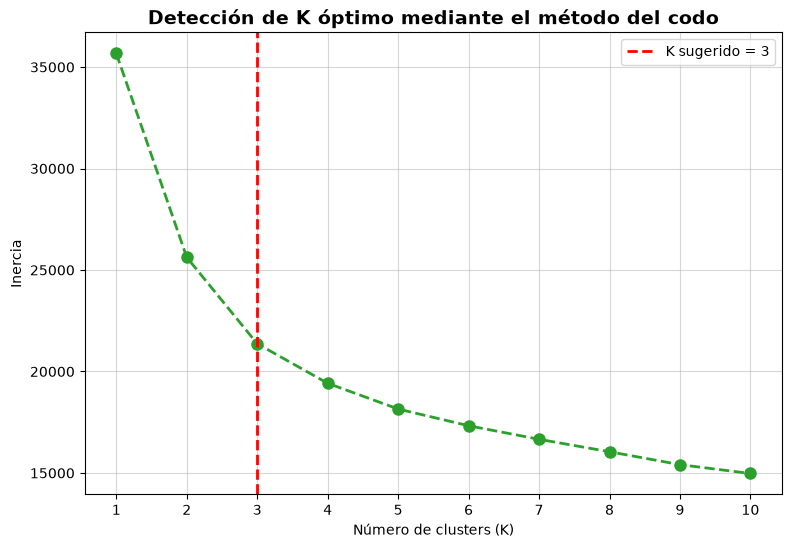

Mejor K según Silhouette Score: 2
Mejor Silhouette Score: 0.3113


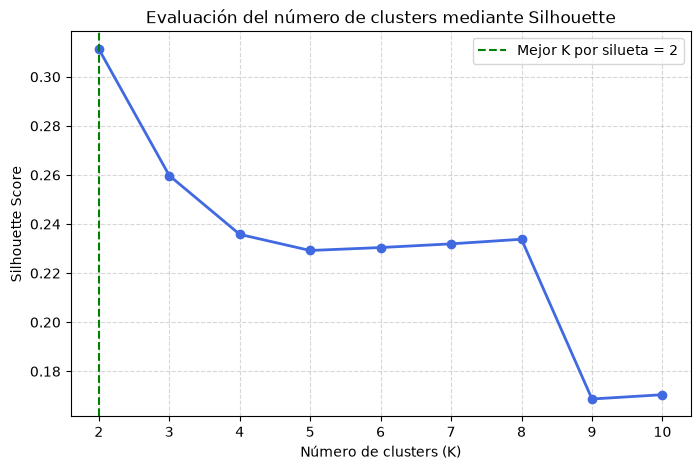

Número definitivo de clusters seleccionado: 3
Inercia del modelo (K=3): 21367.16
Silhouette Score: 0.2598


In [96]:
# MÉTODO DEL CODO: EVALUACIÓN DE INERCIA
inercias = []

# K=1 es válido para calcular la inercia
rango_inercia = range(1, 11)

for k in rango_inercia:

    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10
    )

    kmeans.fit(df_limpia)
    inercias.append(kmeans.inertia_)

# Detectar el número óptimo de clusters mediante KneeLocator
kl = KneeLocator(rango_inercia,inercias,curve="convex",direction="decreasing"
)

k_codo = kl.elbow

print(f"Número de clusters según el método del codo: {k_codo}")

# Visualizar método del codo
plt.figure(figsize=(9, 6))

plt.plot(
    list(rango_inercia),
    inercias,
    marker='o',
    linestyle='--',
    color='#2ca02c',
    linewidth=2,
    markersize=8
)

if k_codo is not None:
    plt.axvline(
        x=k_codo,
        color='red',
        linestyle='--',
        linewidth=2,
        label=f'K sugerido = {k_codo}'
    )

plt.title("Detección de K óptimo mediante el método del codo",
          fontsize=14, fontweight="bold")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia")
plt.xticks(list(rango_inercia))
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()


# MÉTODO DE SILUETA: EVALUACIÓN DE SEPARACIÓN
rango_silueta = range(2, 11)

scores = []

for k in rango_silueta:

    modelo_temp = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas_temp = modelo_temp.fit_predict(df_limpia)

    score_temp = silhouette_score(
        df_limpia,
        etiquetas_temp
    )

    scores.append(score_temp)

# Identificar K con mayor Silhouette Score
k_mejor_silueta = list(rango_silueta)[np.argmax(scores)]

print(f"Mejor K según Silhouette Score: {k_mejor_silueta}")
print(f"Mejor Silhouette Score: {max(scores):.4f}")

# Visualizar método de silueta
plt.figure(figsize=(8, 5))

plt.plot(
    list(rango_silueta),
    scores,
    marker='o',
    color='royalblue',
    linewidth=2
)

plt.axvline(
    x=k_mejor_silueta,
    color='green',
    linestyle='--',
    label=f'Mejor K por silueta = {k_mejor_silueta}'
)

plt.title('Evaluación del número de clusters mediante Silhouette')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(list(rango_silueta))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


# SELECCIÓN DEL K DEFINITIVO
if k_codo is not None and k_codo >= 2:
    k_optimo = k_codo
else:
    k_optimo = k_mejor_silueta

print(f"Número definitivo de clusters seleccionado: {k_optimo}")


# ENTRENAMIENTO DEL MODELO K-MEANS DEFINITIVO
kmeans_final = KMeans(
    n_clusters=k_optimo,
    random_state=42,
    n_init=10
)

etiquetas_clusters = kmeans_final.fit_predict(df_limpia)

# Evaluación final
score = silhouette_score(
    df_limpia,
    etiquetas_clusters
)

print(f"Inercia del modelo (K={k_optimo}): {kmeans_final.inertia_:.2f}")
print(f"Silhouette Score: {score:.4f}")

* Bajo índice de silueta, por tanto se infiere solapamiento de los clusters y poca separación de los mismos.
* Inercia media-baja, por tanto se infiere un agrupamiento de cluster regular, ni tan bueno, ni tan malo. 

### **3.3.3 PCA**

In [97]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(df_limpia)

print("Varianza explicada:", pca.explained_variance_ratio_)

Varianza explicada: [0.29245915 0.16518735]


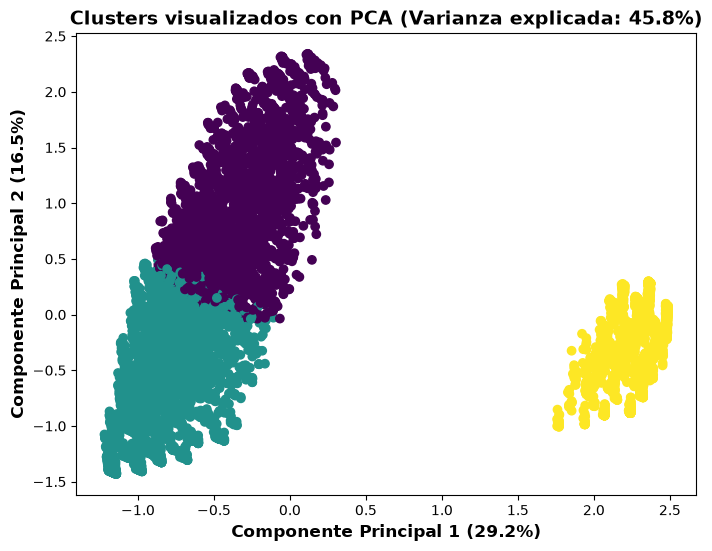

In [98]:
# Calcular porcentaje de varianza explicada
var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
var_acumulada = var_pc1 + var_pc2

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca.iloc[:, 0],
    X_pca.iloc[:, 1],
    c=etiquetas_clusters,
    cmap="viridis"
)

plt.xlabel(
    f"Componente Principal 1 ({var_pc1:.1f}%)",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    f"Componente Principal 2 ({var_pc2:.1f}%)",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    f"Clusters visualizados con PCA (Varianza explicada: {var_acumulada:.1f}%)",
    fontsize=14,
    fontweight="bold"
)

plt.show()

* Los dos componentes principales explican aproximadamente el 45,8% de la varianza total de los datos. Esto significa que la representación en dos dimensiones conserva una parte importante de la variabilidad, aunque no permite visualizar completamente la estructura original de los datos.

* Observaciones: 
    - Uno de los cluster bien separado y relativamente compacto.
    - Solapamiento claro en los otros dos cluster.

In [99]:
# Crear una copia para almacenar los resultados de segmentación
df_segmentacion_resultados = df_segmentacion.copy(deep=True)

# Incorporar las etiquetas de los clusters
df_segmentacion_resultados["clusters"] = etiquetas_clusters

### **3.3.4 Aplicación al problema de negocio**

#### **Porcentajes de abandono por cluster**

Porcentaje de abandono (Churn) por Cluster:


Churn,No,Yes
clusters,,
0,88.6,11.4
1,52.9,47.1
2,92.6,7.4


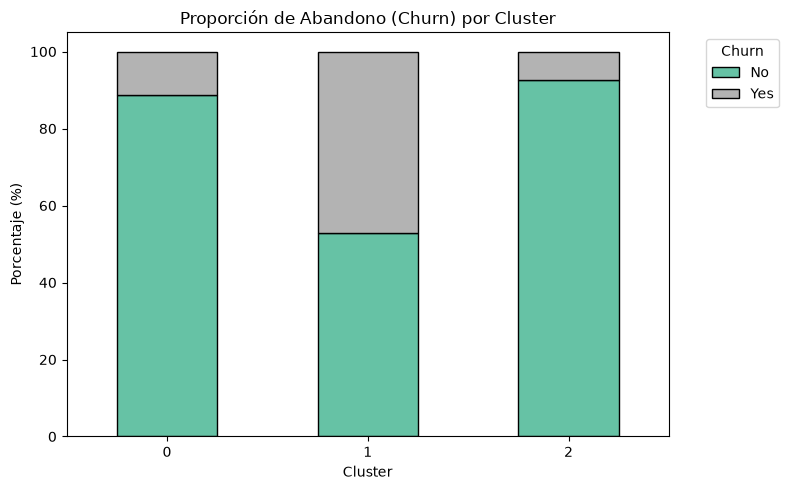

In [100]:
# Calcular porcentaje de abandono por cluster
porcentaje_churn = pd.crosstab(
    df_segmentacion_resultados['clusters'],
    df_segmentacion_resultados['Churn'],
    normalize='index'
) * 100

print("Porcentaje de abandono (Churn) por Cluster:")
display(porcentaje_churn.round(1))

porcentaje_churn.plot(kind='bar', stacked=True, figsize=(8, 5), colormap='Set2', edgecolor='black')

plt.title('Proporción de Abandono (Churn) por Cluster')
plt.xlabel('Cluster')
plt.ylabel('Porcentaje (%)')
plt.legend(title='Churn', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

* Clusters 0 y 2 con bajo porcentaje de abandono
* Cluster 1 con un alto porcentaje de abandono, por tanto podría considerarse un candidato para fijación con estrategias de retención.

#### **Perfilamiento de los clusters**

In [101]:
# Identificar variables numéricas para el perfilamiento
cols_numericas = df_segmentacion_resultados.select_dtypes(
    include=np.number
).columns.drop(
    ['clusters', 'Churn'],
    errors='ignore'
)

# Identificar variables categóricas para el perfilamiento
cols_categoricas = df_segmentacion_resultados.select_dtypes(
    include=['object', 'category', 'bool', 'string']
).columns.drop(
    ['customerID_Hash', 'gender', 'Churn'],
    errors='ignore'
)

print("\nPERFIL NUMÉRICO")

perfil_num = (
    df_segmentacion_resultados
    .groupby('clusters')[cols_numericas]
    .mean()
    .round(2)
)

display(perfil_num)

print("\nPERFIL CATEGÓRICO")

perfil_cat = (
    df_segmentacion_resultados
    .groupby('clusters')[cols_categoricas]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
)

display(perfil_cat)


PERFIL NUMÉRICO


,tenure,MonthlyCharges,TotalCharges
clusters,,,
0,50.19,80.79,4227.14
1,19.98,73.90,1609.78
2,30.55,21.08,662.60



PERFIL CATEGÓRICO


,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod
clusters,,,,,,,,,,,,,,,
0,No,Yes,No,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic)
1,No,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check
2,No,No,No,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check


* Cluster 0: Cliente Multi-Servicio y consolidado.
    - Usuarios que consumen la gama completa de servicios y están profundamente integrados en el ecosistema de la empresa.

* Cluster 1: Cliente Digitales de banda ancha y alto riesgo de fuga.
    - Usuarios de fibra óptica, pero no tienen lealtad a la marca ni consumen servicios extra.

* Cluster 2: Cliente análogo y de bajo impacto.
    - Usuarios de tecnología antigua, fidelizados con contratos estables, pero que no adoptan nuevas tecnologías.


## **3.4 Feature Importance**

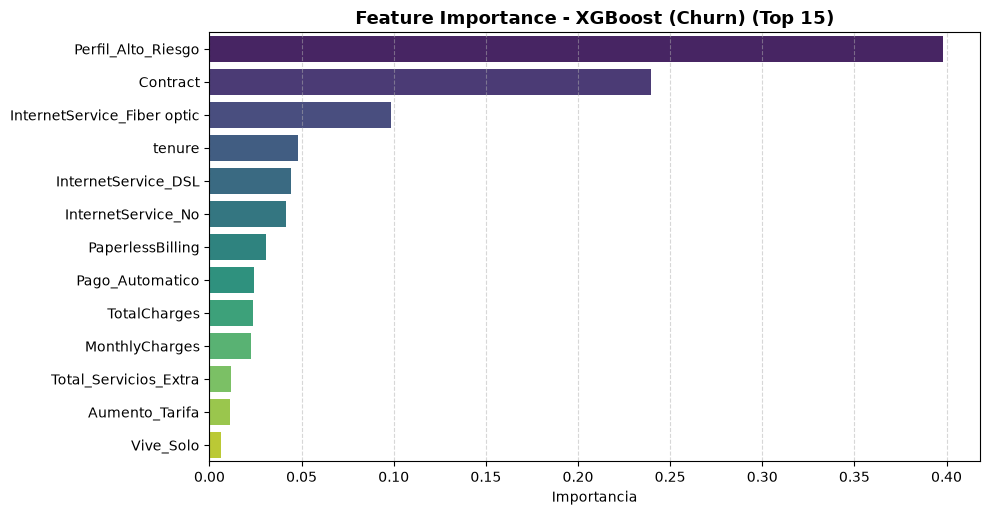

,Feature,Importancia
0,Perfil_Alto_Riesgo,0.398248
1,Contract,0.239602
2,InternetService_Fiber optic,0.098725
3,tenure,0.048004
4,InternetService_DSL,0.044074
5,InternetService_No,0.041424
6,PaperlessBilling,0.030703
7,Pago_Automatico,0.024067
8,TotalCharges,0.023823
9,MonthlyCharges,0.022338


In [102]:
# Visualización de la importancia de las características para el modelo XGBoost
mejor_xgb = modelos_xgb['RandomizedSearchCV']
df_imp_xgb = obtener_feature_importance(
    mejor_xgb,
    top_n=15,
    titulo="Feature Importance - XGBoost (Churn)"
)
display(df_imp_xgb.head(15))

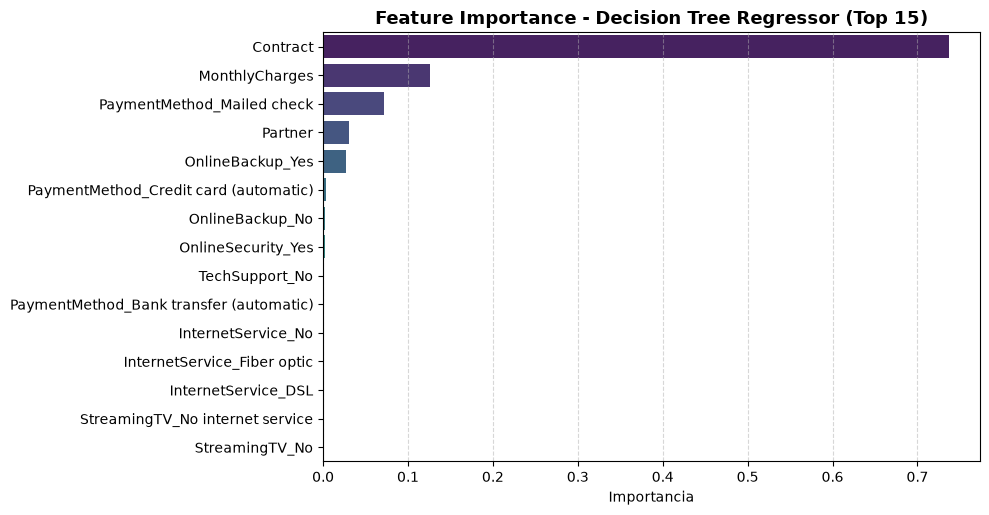

In [103]:
# Visualización de la importancia de las características para el modelo Decision Tree Regressor
mejor_dtr = modelos_dtr['GridSearchCV']
df_imp_dtr = obtener_feature_importance(
    mejor_dtr,
    top_n=15,
    titulo="Feature Importance - Decision Tree Regressor"
)

* Para este item podemos determinar una conexión lógica entre los segmentos del modelo no supervisado y las variables más importantes usadas en los modelos de clasificación y regresión, sobre todo en la explicabilidad del comportamiento de los usuarios y su contexto previo al abandono.

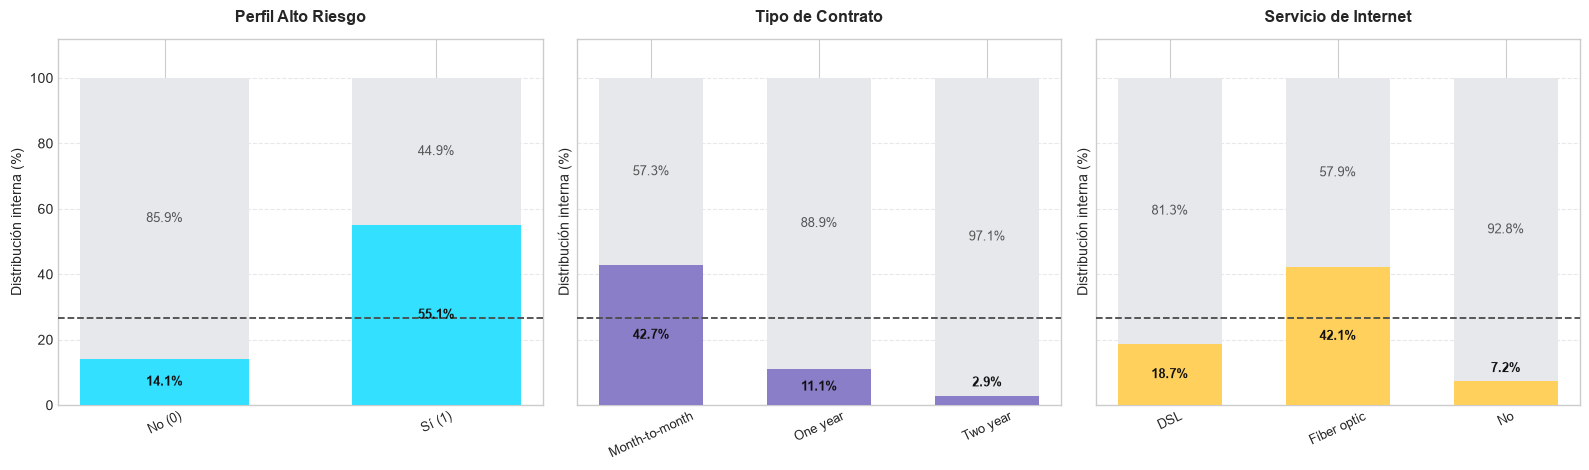

In [109]:
df_plot = mejor_xgb.named_steps['ingenieria_caracteristicas'].transform(X_clf_train).copy()
df_plot['Churn'] = np.asarray(y_clf_train)

vars_a_graficar = ['Perfil_Alto_Riesgo', 'Contract', 'InternetService']
titulos = ['Perfil Alto Riesgo', 'Tipo de Contrato', 'Servicio de Internet']
colores = ['#33E0FF', '#8B7EC8', '#FFD15C']

promedio_global = df_plot['Churn'].mean() * 100

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)

for idx, (ax, var, titulo) in enumerate(zip(axes, vars_a_graficar, titulos)):
    serie = df_plot[var]

    if set(serie.dropna().unique()).issubset({0, 1}):
        grupos = serie.map({0: 'No (0)', 1: 'Sí (1)'})
    else:
        grupos = serie.astype(str)

    tabla = pd.crosstab(grupos, df_plot['Churn'], normalize='index') * 100
    fuga = tabla[1]
    retenidos = tabla[0]
    categorias = tabla.index.astype(str)

    barras_fuga = ax.bar(
        categorias, fuga.values, color=colores[idx], width=0.62, zorder=3, label='Se fuga (Churn)'
    )
    barras_ret = ax.bar(
        categorias, retenidos.values, bottom=fuga.values, color='#E6E8EC', width=0.62, zorder=3, label='Se queda (100% total)'
    )

    ax.axhline(
        promedio_global, color='#4A4A4A', linestyle='--', linewidth=1.3, zorder=4,
        label=f'Promedio global ({promedio_global:.1f}%)'
    )

    for b_fuga, b_ret in zip(barras_fuga, barras_ret):
        h_fuga = b_fuga.get_height()
        h_ret = b_ret.get_height()
        x_pos = b_fuga.get_x() + b_fuga.get_width() / 2

        ax.text(
            x_pos, h_fuga / 2 if h_fuga > 8 else h_fuga + 2, f'{h_fuga:.1f}%',
            ha='center', va='center' if h_fuga > 8 else 'bottom',
            fontsize=9.5, fontweight='bold', color='#111111', zorder=5
        )

        if h_ret > 10:
            ax.text(
                x_pos, h_fuga + (h_ret / 2), f'{h_ret:.1f}%',
                ha='center', va='center', fontsize=9, color='#555555', zorder=5
            )

    ax.set_title(titulo, fontsize=11.5, fontweight='bold', pad=12)
    ax.set_ylabel('Distribución interna (%)', fontsize=10)
    ax.set_ylim(0, 112)
    ax.tick_params(axis='x', rotation=25, labelsize=9.5)
    ax.grid(axis='y', linestyle='--', alpha=0.45, zorder=0)


plt.tight_layout()
plt.show()